In [2]:
%pip install pandas openpyxl matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

df = pd.read_excel(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\telcom_data (2).xlsx"
)

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (150001, 55)


,Bearer Id,Start,Start ms,End,End ms,Dur. (ms),IMSI,MSISDN/Number,IMEI,Last Location Name,...,Youtube DL (Bytes),Youtube UL (Bytes),Netflix DL (Bytes),Netflix UL (Bytes),Gaming DL (Bytes),Gaming UL (Bytes),Other DL (Bytes),Other UL (Bytes),Total UL (Bytes),Total DL (Bytes)
0,13114483460844900352,2019-04-04 12:01:18,770.0,2019-04-25 14:35:31,662.0,1823652.0,2.082014e+14,3.366496e+10,3.552121e+13,9164566995485190,...,15854611.0,2501332.0,8198936.0,9656251.0,278082303.0,14344150.0,171744450.0,8814393.0,36749741.0,308879636.0
1,13114483482878900224,2019-04-09 13:04:04,235.0,2019-04-25 08:15:48,606.0,1365104.0,2.082019e+14,3.368185e+10,3.579401e+13,L77566A,...,20247395.0,19111729.0,18338413.0,17227132.0,608750074.0,1170709.0,526904238.0,15055145.0,53800391.0,653384965.0
2,13114483484080500736,2019-04-09 17:42:11,1.0,2019-04-25 11:58:13,652.0,1361762.0,2.082003e+14,3.376063e+10,3.528151e+13,D42335A,...,19725661.0,14699576.0,17587794.0,6163408.0,229584621.0,395630.0,410692588.0,4215763.0,27883638.0,279807335.0
3,13114483485442799616,2019-04-10 00:31:25,486.0,2019-04-25 07:36:35,171.0,1321509.0,2.082014e+14,3.375034e+10,3.535661e+13,T21824A,...,21388122.0,15146643.0,13994646.0,1097942.0,799538153.0,10849722.0,749039933.0,12797283.0,43324218.0,846028530.0
4,13114483499480700928,2019-04-12 20:10:23,565.0,2019-04-25 10:40:32,954.0,1089009.0,2.082014e+14,3.369980e+10,3.540701e+13,D88865A,...,15259380.0,18962873.0,17124581.0,415218.0,527707248.0,3529801.0,550709500.0,13910322.0,38542814.0,569138589.0


In [4]:
# Check duplicates and missing customer/device information
print("Duplicate rows:", df.duplicated().sum())

columns = ["MSISDN/Number", "Handset Type", "Handset Manufacturer"]

print("\nMissing values:")
print(df[columns].isna().sum())

display(df[columns].head())

Duplicate rows: 0

Missing values:
MSISDN/Number           1066
Handset Type             572
Handset Manufacturer     572
dtype: int64


,MSISDN/Number,Handset Type,Handset Manufacturer
0,3.366496e+10,Samsung Galaxy A5 Sm-A520F,Samsung
1,3.368185e+10,Samsung Galaxy J5 (Sm-J530),Samsung
2,3.376063e+10,Samsung Galaxy A8 (2018),Samsung
3,3.375034e+10,undefined,undefined
4,3.369980e+10,Samsung Sm-G390F,Samsung


In [5]:
# Keep rows with a customer ID for customer-level analysis
task1_df = df.dropna(subset=["MSISDN/Number"]).copy()

# Label missing and undefined device information
device_columns = ["Handset Type", "Handset Manufacturer"]

for column in device_columns:
    task1_df[column] = task1_df[column].fillna("Unknown").str.strip()
    unknown = task1_df[column].str.lower().isin(["undefined", "unknown", ""])
    task1_df.loc[unknown, column] = "Unknown"

print("Rows available:", len(task1_df))
print("Unique customers:", task1_df["MSISDN/Number"].nunique())

Rows available: 148935
Unique customers: 106856


In [6]:
# Select the most frequently recorded value for each customer
def most_common(values):
    return values.mode().iloc[0]

customers = (
    task1_df.groupby("MSISDN/Number")[device_columns]
    .agg(most_common)
)

# Exclude unknown handsets from the ranking
top_10_handsets = (
    customers.loc[customers["Handset Type"] != "Unknown", "Handset Type"]
    .value_counts()
    .head(10)
    .rename_axis("Handset")
    .reset_index(name="Customer count")
)

display(top_10_handsets)

,Handset,Customer count
0,Huawei B528S-23A,10615
1,Apple iPhone 6S (A1688),6759
2,Apple iPhone 6 (A1586),6260
3,Apple iPhone 7 (A1778),4699
4,Apple iPhone Se (A1723),3754
5,Apple iPhone 8 (A1905),3543
6,Samsung Galaxy S8 (Sm-G950F),3245
7,Apple iPhone Xr (A2105),3072
8,Samsung Galaxy J5 (Sm-J530),2748
9,Samsung Galaxy A5 Sm-A520F,2708


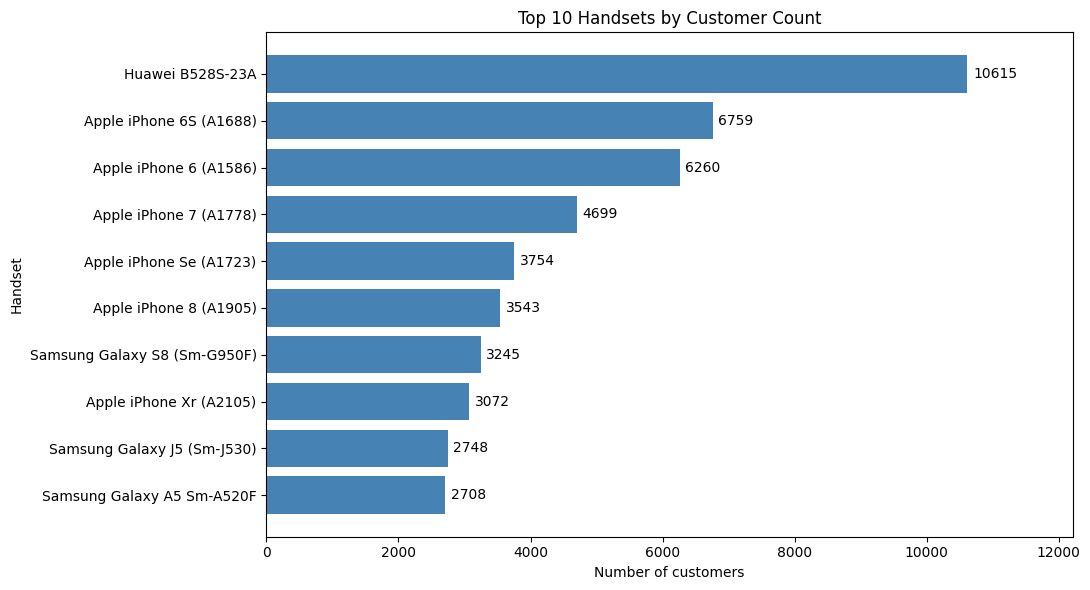

In [7]:
import matplotlib.pyplot as plt

chart_data = top_10_handsets.sort_values("Customer count")

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    chart_data["Handset"],
    chart_data["Customer count"],
    color="steelblue"
)

ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_title("Top 10 Handsets by Customer Count")
ax.set_xlabel("Number of customers")
ax.set_ylabel("Handset")
ax.set_xlim(0, chart_data["Customer count"].max() * 1.15)

plt.tight_layout()
plt.show()

In [8]:
top_3_manufacturers = (
    customers.loc[
        customers["Handset Manufacturer"] != "Unknown",
        "Handset Manufacturer"
    ]
    .value_counts()
    .head(3)
    .rename_axis("Manufacturer")
    .reset_index(name="Customer count")
)

# Percentage of all identified customers, including unknown devices
top_3_manufacturers["Customer share (%)"] = (
    top_3_manufacturers["Customer count"] / len(customers) * 100
).round(2)

display(top_3_manufacturers)

,Manufacturer,Customer count,Customer share (%)
0,Apple,42592,39.86
1,Samsung,30780,28.81
2,Huawei,21692,20.30


In [9]:
manufacturer_tables = []

for manufacturer in top_3_manufacturers["Manufacturer"]:
    selected = customers[
        (customers["Handset Manufacturer"] == manufacturer)
        & (customers["Handset Type"] != "Unknown")
    ]

    top_5 = (
        selected["Handset Type"]
        .value_counts()
        .head(5)
        .rename_axis("Handset")
        .reset_index(name="Customer count")
    )

    top_5.insert(0, "Manufacturer", manufacturer)
    manufacturer_tables.append(top_5)

top_5_per_manufacturer = pd.concat(
    manufacturer_tables, ignore_index=True
)

display(top_5_per_manufacturer)

,Manufacturer,Handset,Customer count
0,Apple,Apple iPhone 6S (A1688),6759
1,Apple,Apple iPhone 6 (A1586),6260
2,Apple,Apple iPhone 7 (A1778),4699
3,Apple,Apple iPhone Se (A1723),3754
4,Apple,Apple iPhone 8 (A1905),3543
5,Samsung,Samsung Galaxy S8 (Sm-G950F),3245
6,Samsung,Samsung Galaxy J5 (Sm-J530),2748
7,Samsung,Samsung Galaxy A5 Sm-A520F,2708
8,Samsung,Samsung Galaxy J3 (Sm-J330),2589
9,Samsung,Samsung Galaxy S7 (Sm-G930X),2292


### Task 1 — Findings and recommendations

- Apple is the leading manufacturer, representing 39.86% of identified
  customers, followed by Samsung (28.81%) and Huawei (20.30%).
  Together, they account for approximately 88.97% of customers.

- Huawei B528S-23A is the most frequently assigned device, with 10,615
  customers. Apple has six models in the overall top 10.

- Prioritize compatibility testing and customer support for these
  manufacturers and their most common models.

- Test device-specific offers and upgrade campaigns. Use customer usage,
  revenue, and campaign response data to evaluate their effectiveness.

- Investigate the usage needs of the large Huawei B528S-23A customer
  group before designing targeted data bundles.

### Method and limitations

- Each customer is represented by their most frequently recorded handset
  and manufacturer; ties are resolved alphabetically.
- Rows without customer IDs are excluded from customer-level analysis.
- Unknown devices are excluded from rankings, but their customers remain
  in the denominator for customer shares.
- These findings describe the historical dataset, not current market share.

In [10]:
# Find duration and data-volume columns
usage_columns = [
    column for column in task1_df.columns
    if "Dur." in column or "(Bytes)" in column
]

print("Usage columns:")
for column in usage_columns:
    print(column)

print("\nMissing values:")
print(task1_df[usage_columns].isna().sum())

Usage columns:
Dur. (ms)
TCP DL Retrans. Vol (Bytes)
TCP UL Retrans. Vol (Bytes)
HTTP DL (Bytes)
HTTP UL (Bytes)
Dur. (ms).1
Social Media DL (Bytes)
Social Media UL (Bytes)
Google DL (Bytes)
Google UL (Bytes)
Email DL (Bytes)
Email UL (Bytes)
Youtube DL (Bytes)
Youtube UL (Bytes)
Netflix DL (Bytes)
Netflix UL (Bytes)
Gaming DL (Bytes)
Gaming UL (Bytes)
Other DL (Bytes)
Other UL (Bytes)
Total UL (Bytes)
Total DL (Bytes)

Missing values:
Dur. (ms)                          0
TCP DL Retrans. Vol (Bytes)    87796
TCP UL Retrans. Vol (Bytes)    96192
HTTP DL (Bytes)                81171
HTTP UL (Bytes)                81508
Dur. (ms).1                        0
Social Media DL (Bytes)            0
Social Media UL (Bytes)            0
Google DL (Bytes)                  0
Google UL (Bytes)                  0
Email DL (Bytes)                   0
Email UL (Bytes)                   0
Youtube DL (Bytes)                 0
Youtube UL (Bytes)                 0
Netflix DL (Bytes)                 0
Netfl

In [11]:
# Show only columns containing missing values
missing = task1_df[usage_columns].isna().sum()
print("Columns with missing values:")
print(missing[missing > 0].to_string())

# Compare duration fields with elapsed time in seconds
sample = task1_df.head(5)

duration_check = pd.DataFrame({
    "Timestamp difference (seconds)": (
        pd.to_datetime(sample["End"])
        - pd.to_datetime(sample["Start"])
    ).dt.total_seconds(),
    "Dur. (ms)": sample["Dur. (ms)"],
    "Dur. (ms).1 divided by 1000": sample["Dur. (ms).1"] / 1000
})

display(duration_check)

Columns with missing values:
TCP DL Retrans. Vol (Bytes)    87796
TCP UL Retrans. Vol (Bytes)    96192
HTTP DL (Bytes)                81171
HTTP UL (Bytes)                81508


,Timestamp difference (seconds),Dur. (ms),Dur. (ms).1 divided by 1000
0,1823653.0,1823652.0,1823652.892
1,1365104.0,1365104.0,1365104.371
2,1361762.0,1361762.0,1361762.651
3,1321510.0,1321509.0,1321509.685
4,1089009.0,1089009.0,1089009.389


In [12]:
usage_df = task1_df.copy()

# Convert milliseconds to seconds
usage_df["Duration_seconds"] = usage_df["Dur. (ms).1"] / 1000

# Combine download and upload volume for each application
apps = ["Social Media", "Google", "Email", "Youtube",
        "Netflix", "Gaming", "Other"]

for app in apps:
    usage_df[f"{app} Total (Bytes)"] = (
        usage_df[f"{app} DL (Bytes)"]
        + usage_df[f"{app} UL (Bytes)"]
    )

# Sum usage for each customer
sum_columns = [
    "Duration_seconds", "Total DL (Bytes)", "Total UL (Bytes)"
] + [f"{app} Total (Bytes)" for app in apps]

grouped = usage_df.groupby("MSISDN/Number")

customer_usage = grouped[sum_columns].sum(min_count=1)
customer_usage.insert(0, "Session_count", grouped.size())

customer_usage["Total Data (Bytes)"] = (
    customer_usage["Total DL (Bytes)"]
    + customer_usage["Total UL (Bytes)"]
)

print("Customers:", len(customer_usage))
display(customer_usage.head().T)

Customers: 106856


MSISDN/Number,3.360100e+10,3.360100e+10,3.360100e+10,3.360101e+10,3.360101e+10
Session_count,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
Duration_seconds,1.167201e+05,1.812310e+05,1.349694e+05,4.987802e+04,3.710445e+04
Total DL (Bytes),8.426375e+08,1.207552e+08,5.566597e+08,4.019932e+08,1.363130e+09
Total UL (Bytes),3.605311e+07,3.610446e+07,3.930682e+07,2.032753e+07,9.428053e+07
Social Media Total (Bytes),2.232135e+06,2.660565e+06,3.195623e+06,2.802940e+05,2.912542e+06
Google Total (Bytes),4.389005e+06,5.334863e+06,3.443126e+06,9.678493e+06,1.849962e+07
Email Total (Bytes),1.331362e+06,3.307781e+06,3.205380e+06,2.284670e+06,3.305469e+06
Youtube Total (Bytes),2.162455e+07,1.243222e+07,2.133357e+07,6.977321e+06,4.153300e+07
Netflix Total (Bytes),2.718098e+07,1.122176e+07,1.935390e+07,1.942092e+06,4.920172e+07
Gaming Total (Bytes),8.124587e+08,1.197501e+08,5.388277e+08,3.911261e+08,1.314798e+09


In [13]:
import numpy as np

print(
    "Session counts match:",
    customer_usage["Session_count"].sum() == len(usage_df)
)

print(
    "Usage totals match:",
    np.allclose(
        customer_usage[sum_columns].sum(),
        usage_df[sum_columns].sum()
    )
)

print(
    "Missing values in customer summary:",
    customer_usage.isna().sum().sum()
)

# Display a readable preview without scientific notation
preview = customer_usage.head().copy()
preview.index = preview.index.map(lambda value: f"{value:.0f}")

with pd.option_context("display.float_format", "{:,.2f}".format):
    display(preview.T)

Session counts match: True
Usage totals match: True
Missing values in customer summary: 0


MSISDN/Number,33601001722,33601001754,33601002511,33601007832,33601008617
Session_count,1.00,1.00,1.00,1.00,2.00
Duration_seconds,"116,720.14","181,230.96","134,969.37","49,878.02","37,104.45"
Total DL (Bytes),"842,637,466.00","120,755,184.00","556,659,663.00","401,993,172.00","1,363,130,417.00"
Total UL (Bytes),"36,053,108.00","36,104,459.00","39,306,820.00","20,327,526.00","94,280,527.00"
Social Media Total (Bytes),"2,232,135.00","2,660,565.00","3,195,623.00","280,294.00","2,912,542.00"
Google Total (Bytes),"4,389,005.00","5,334,863.00","3,443,126.00","9,678,493.00","18,499,616.00"
Email Total (Bytes),"1,331,362.00","3,307,781.00","3,205,380.00","2,284,670.00","3,305,469.00"
Youtube Total (Bytes),"21,624,548.00","12,432,223.00","21,333,570.00","6,977,321.00","41,533,002.00"
Netflix Total (Bytes),"27,180,981.00","11,221,763.00","19,353,900.00","1,942,092.00","49,201,724.00"
Gaming Total (Bytes),"812,458,661.00","119,750,078.00","538,827,713.00","391,126,127.00","1,314,797,820.00"


### Task 1.1 — Customer usage aggregation

Aggregated 148,935 session records into 106,856 customer summaries.

For each customer, calculated:
- Number of session records.
- Total session duration in seconds.
- Total download and upload volume in bytes.
- Combined download and upload volume for each application.
- Total network data volume: total download + total upload.

Validation confirmed that aggregation preserved session counts and
usage totals. The resulting summary contains no missing values.

Duration was calculated using `Dur. (ms).1 / 1000`.
Application volumes do not reconcile with the network total, so they
are analysed separately rather than treated as shares of that total.

In [14]:
variable_summary = pd.DataFrame({
    "Data type": customer_usage.dtypes.astype(str),
    "Missing values": customer_usage.isna().sum()
})

variable_summary["Meaning"] = [
    "Number of session records" if column == "Session_count"
    else "Total session duration in seconds" if column == "Duration_seconds"
    else "Total downloaded bytes" if column == "Total DL (Bytes)"
    else "Total uploaded bytes" if column == "Total UL (Bytes)"
    else "Total network download + upload bytes" if column == "Total Data (Bytes)"
    else "Application download + upload bytes"
    for column in variable_summary.index
]

display(variable_summary)

,Data type,Missing values,Meaning
Session_count,int64,0,Number of session records
Duration_seconds,float64,0,Total session duration in seconds
Total DL (Bytes),float64,0,Total downloaded bytes
Total UL (Bytes),float64,0,Total uploaded bytes
Social Media Total (Bytes),float64,0,Application download + upload bytes
Google Total (Bytes),float64,0,Application download + upload bytes
Email Total (Bytes),float64,0,Application download + upload bytes
Youtube Total (Bytes),float64,0,Application download + upload bytes
Netflix Total (Bytes),float64,0,Application download + upload bytes
Gaming Total (Bytes),float64,0,Application download + upload bytes


In [15]:
# Detect potential outliers without changing the data
Q1 = customer_usage.quantile(0.25)
Q3 = customer_usage.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_flags = (
    customer_usage.lt(lower_bound)
    | customer_usage.gt(upper_bound)
)

outlier_summary = pd.DataFrame({
    "Missing values": customer_usage.isna().sum(),
    "Lower bound": lower_bound,
    "Upper bound": upper_bound,
    "Potential outliers": outlier_flags.sum(),
    "Outlier percentage": (
        outlier_flags.mean() * 100
    ).round(2)
})

print(outlier_summary.round(2).to_string())

                            Missing values   Lower bound   Upper bound  Potential outliers  Outlier percentage
Session_count                            0 -5.000000e-01  3.500000e+00                3251                3.04
Duration_seconds                         0 -8.092914e+04  3.250375e+05                8052                7.54
Total DL (Bytes)                         0 -4.239791e+08  1.546171e+09                4708                4.41
Total UL (Bytes)                         0 -7.609303e+06  1.097368e+08                7456                6.98
Social Media Total (Bytes)               0 -1.933060e+06  6.451850e+06                4296                4.02
Google Total (Bytes)                     0 -4.965520e+06  2.412290e+07                5883                5.51
Email Total (Bytes)                      0 -1.584594e+06  7.106272e+06                5645                5.28
Youtube Total (Bytes)                    0 -1.031424e+07  6.687331e+07                6459                6.04
N

In [16]:
# Descriptive statistics before outlier treatment
basic_statistics = customer_usage.describe().T

basic_statistics["median"] = customer_usage.median()
basic_statistics["variance"] = customer_usage.var()
basic_statistics["IQR"] = (
    customer_usage.quantile(0.75)
    - customer_usage.quantile(0.25)
)
basic_statistics["skewness"] = customer_usage.skew()

with pd.option_context("display.float_format", "{:,.2f}".format):
    print(basic_statistics.to_string())

                                count           mean            std           min            25%            50%            75%              max         median                   variance            IQR  skewness
Session_count              106,856.00           1.39           0.81          1.00           1.00           1.00           2.00            18.00           1.00                       0.65           1.00      3.35
Duration_seconds           106,856.00     146,167.92     186,358.95      7,142.99      71,308.34     102,740.22     172,800.00    18,553,763.49     102,740.22          34,729,658,532.95     101,491.66     20.54
Total DL (Bytes)           106,856.00 633,652,680.89 464,555,056.46  8,827,082.00 314,827,063.75 570,367,723.00 807,364,490.25 8,156,743,493.00 570,367,723.00 215,811,400,483,495,456.00 492,537,426.50      2.15
Total UL (Bytes)           106,856.00  57,309,422.41  35,657,649.75  2,866,892.00  36,395,474.75  46,793,865.50  65,731,993.00   729,577,380.00  46,793,865.

In [17]:
# Separate copy for Task 1.2 outlier treatment
customer_usage_clean = customer_usage.copy()

# Preserve actual session counts; calculate total data from DL + UL
treatment_columns = customer_usage.columns.drop(
    ["Session_count", "Total Data (Bytes)"]
)

treatment_log = []

for column in treatment_columns:
    original = customer_usage[column]

    # Use the original column's mean, excluding missing values
    replacement_mean = original.mean()
    replace_mask = outlier_flags[column] | original.isna()

    customer_usage_clean[column] = original.mask(
        replace_mask, replacement_mean
    )

    treatment_log.append({
        "Variable": column,
        "Values replaced": int(replace_mask.sum()),
        "Replacement mean": replacement_mean
    })

# Preserve the relationship: total data = download + upload
customer_usage_clean["Total Data (Bytes)"] = (
    customer_usage_clean["Total DL (Bytes)"]
    + customer_usage_clean["Total UL (Bytes)"]
)

treatment_summary = pd.DataFrame(treatment_log)

print(treatment_summary.round(2).to_string(index=False))
print(
    "\nMissing values after treatment:",
    customer_usage_clean.isna().sum().sum()
)

                  Variable  Values replaced  Replacement mean
          Duration_seconds             8052         146167.92
          Total DL (Bytes)             4708      633652680.89
          Total UL (Bytes)             7456       57309422.41
Social Media Total (Bytes)             4296        2547966.82
      Google Total (Bytes)             5883       10882434.42
       Email Total (Bytes)             5645        3148795.81
     Youtube Total (Bytes)             6459       31558399.28
     Netflix Total (Bytes)             6371       31538332.31
      Gaming Total (Bytes)             4396      599769010.72
       Other Total (Bytes)             4418      598508764.28

Missing values after treatment: 0


In [18]:
comparison = pd.DataFrame({
    "Mean before": customer_usage.mean(),
    "Mean after": customer_usage_clean.mean(),
    "Std before": customer_usage.std(),
    "Std after": customer_usage_clean.std()
})

comparison["Std reduction (%)"] = (
    (1 - comparison["Std after"] / comparison["Std before"]) * 100
)

with pd.option_context("display.float_format", "{:,.2f}".format):
    print(comparison.to_string())

print(
    "\nSession counts unchanged:",
    customer_usage_clean["Session_count"].equals(
        customer_usage["Session_count"]
    )
)

print(
    "Total data equals download + upload:",
    np.allclose(
        customer_usage_clean["Total Data (Bytes)"],
        customer_usage_clean["Total DL (Bytes)"]
        + customer_usage_clean["Total UL (Bytes)"]
    )
)

                              Mean before     Mean after     Std before      Std after  Std reduction (%)
Session_count                        1.39           1.39           0.81           0.81               0.00
Duration_seconds               146,167.92     116,776.28     186,358.95      68,222.84              63.39
Total DL (Bytes)           633,652,680.89 570,588,899.64 464,555,056.46 327,256,623.48              29.55
Total UL (Bytes)            57,309,422.41  50,491,886.14  35,657,649.75  20,052,654.43              43.76
Social Media Total (Bytes)   2,547,966.82   2,306,856.89   1,908,038.04   1,384,352.64              27.45
Google Total (Bytes)        10,882,434.42   9,676,310.06   7,544,861.44   4,900,679.93              35.05
Email Total (Bytes)          3,148,795.81   2,803,580.86   2,222,400.10   1,463,576.55              34.14
Youtube Total (Bytes)       31,558,399.28  27,913,436.27  21,294,917.68  13,244,519.64              37.80
Netflix Total (Bytes)       31,538,332.31  27,

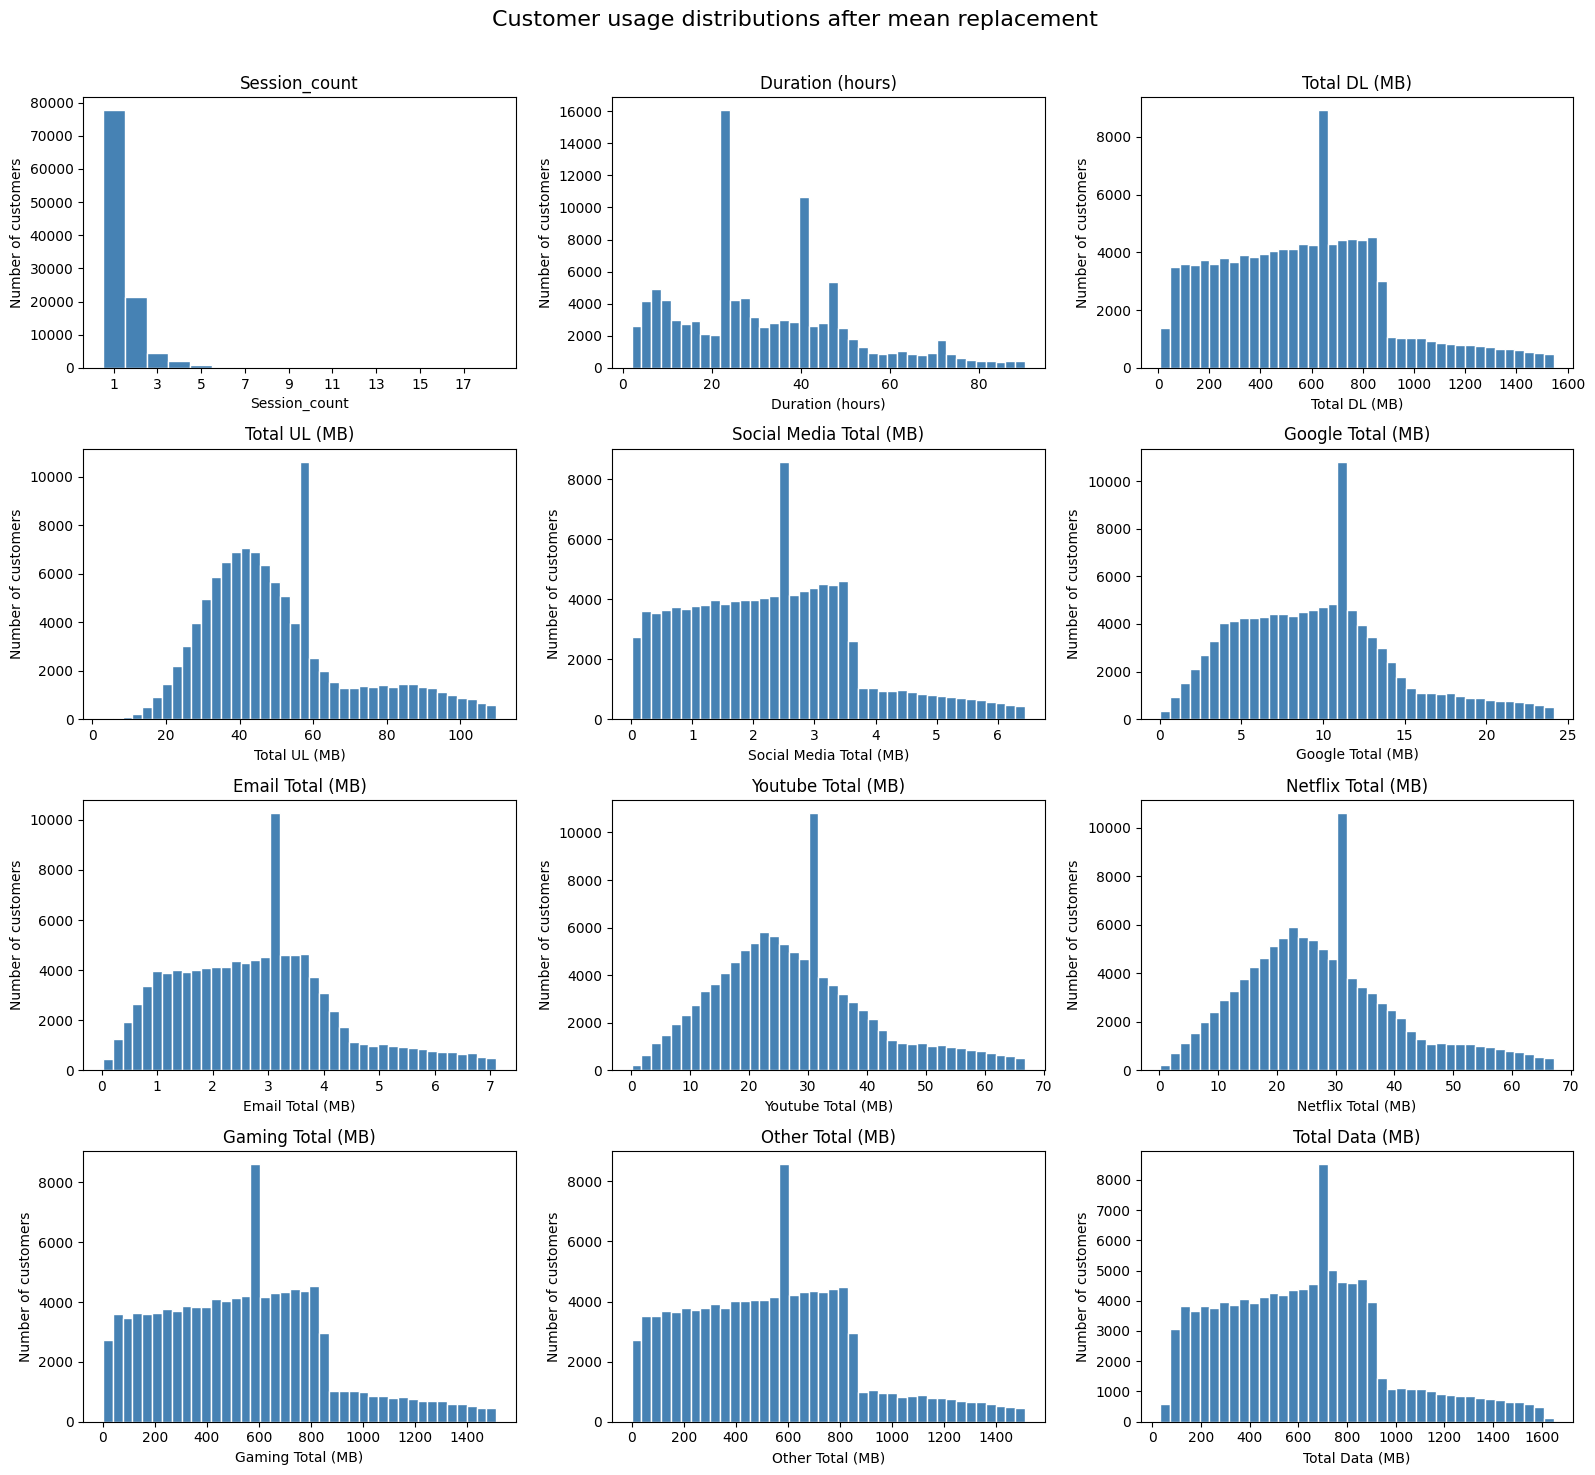

In [19]:
import matplotlib.pyplot as plt

# Convert units for readable chart axes
plot_data = customer_usage_clean.copy()
plot_data["Duration_seconds"] /= 3600

plot_data = plot_data.rename(
    columns={"Duration_seconds": "Duration (hours)"}
)

byte_columns = [
    column for column in plot_data.columns
    if "(Bytes)" in column
]

for column in byte_columns:
    plot_data[column] /= 1_000_000

plot_data = plot_data.rename(
    columns={
        column: column.replace("(Bytes)", "(MB)")
        for column in byte_columns
    }
)

fig, axes = plt.subplots(4, 3, figsize=(16, 15))

for ax, column in zip(axes.flat, plot_data.columns):
    values = plot_data[column]

    if column == "Session_count":
        bins = range(1, int(values.max()) + 2)
        ax.hist(values, bins=bins, align="left",
                color="steelblue", edgecolor="white")
        ax.set_xticks(range(1, int(values.max()) + 1, 2))
    else:
        ax.hist(values, bins=40,
                color="steelblue", edgecolor="white")

    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of customers")

fig.suptitle(
    "Customer usage distributions after mean replacement",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [20]:
from pathlib import Path
import os

chart_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
) / "task1_2_distributions.png"

fig.savefig(chart_path, dpi=150, bbox_inches="tight")
os.startfile(str(chart_path))

### Task 1.2 — Univariate analysis findings

- **Session count:** Most customers have one session, followed by two.
  Customers with many sessions are relatively uncommon. Actual session
  counts were preserved.

- **Duration:** Customer durations vary considerably, with visible peaks
  and a tail toward longer durations. Mean replacement reduced the
  standard deviation by 63.39%.

- **Download and upload:** Download volumes are substantially larger
  than upload volumes. Both distributions retain upper tails after treatment.

- **Social Media:** Most treated values are below approximately 4 MB,
  with fewer customers at higher volumes.

- **Google:** Values concentrate around 5–12 MB, with a tail toward
  higher usage.

- **Email:** Values mainly concentrate around 1–4 MB, with fewer
  customers at higher volumes.

- **YouTube and Netflix:** Both have similar distribution shapes,
  concentrating around 15–35 MB with upper tails.

- **Gaming and Other:** These variables have much larger recorded
  volumes than the other application categories and retain upper tails.

- **Total data:** The distribution broadly resembles download volume.
  Its standard deviation decreased by 31.46% after treatment.

### Interpretation limitations

These plots describe the treated analysis copy. Replacing flagged values
with column means creates artificial peaks and reduces variability.
These peaks should not be interpreted as natural customer groups.

Original customer totals remain available in `customer_usage`.
Application volumes are not treated as mutually exclusive shares of
network traffic because they do not reconcile with the network total.

Chart units: duration in hours and data in decimal MB (1 MB = 1,000,000 bytes).

In [21]:
import matplotlib.pyplot as plt
from pathlib import Path
import os

apps = ["Social Media", "Google", "Email", "Youtube",
        "Netflix", "Gaming", "Other"]

# Reproducible sample for readable scatter plots
sample = customer_usage_clean.sample(
    n=min(5000, len(customer_usage_clean)),
    random_state=42
)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, app in zip(axes.flat, apps):
    column = f"{app} Total (Bytes)"

    ax.scatter(
        sample[column] / 1_000_000,
        sample["Total Data (Bytes)"] / 1_000_000,
        s=8, alpha=0.2, color="steelblue"
    )

    ax.set_title(f"{app} vs total data")
    ax.set_xlabel(f"{app} usage (MB)")
    ax.set_ylabel("Total data (MB)")

for ax in axes.flat[len(apps):]:
    ax.set_visible(False)

fig.suptitle(
    "Application usage vs total data — treated customer sample",
    fontsize=15
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

scatter_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
) / "task1_2_scatterplots_v2.png"

fig.savefig(scatter_path, dpi=150, bbox_inches="tight")
plt.close(fig)
os.startfile(str(scatter_path))

# Correlations use all customers, not just the plotted sample
app_columns = [f"{app} Total (Bytes)" for app in apps]

correlation_comparison = pd.DataFrame({
    "Original Pearson r": customer_usage[app_columns].corrwith(
        customer_usage["Total Data (Bytes)"]
    ),
    "Treated Pearson r": customer_usage_clean[app_columns].corrwith(
        customer_usage_clean["Total Data (Bytes)"]
    )
})

print(correlation_comparison.round(3).to_string())

                            Original Pearson r  Treated Pearson r
Social Media Total (Bytes)               0.624              0.351
Google Total (Bytes)                     0.682              0.391
Email Total (Bytes)                      0.664              0.373
Youtube Total (Bytes)                    0.705              0.417
Netflix Total (Bytes)                    0.705              0.418
Gaming Total (Bytes)                     0.997              0.985
Other Total (Bytes)                      0.619              0.343


In [22]:
apps = ["Social Media", "Google", "Email", "Youtube",
        "Netflix", "Gaming", "Other"]

app_columns = [f"{app} Total (Bytes)" for app in apps]

correlation_comparison = pd.DataFrame({
    "Original Pearson r": customer_usage[app_columns].corrwith(
        customer_usage["Total Data (Bytes)"]
    ),
    "Treated Pearson r": customer_usage_clean[app_columns].corrwith(
        customer_usage_clean["Total Data (Bytes)"]
    )
})

print(correlation_comparison.round(3).to_string())

                            Original Pearson r  Treated Pearson r
Social Media Total (Bytes)               0.624              0.351
Google Total (Bytes)                     0.682              0.391
Email Total (Bytes)                      0.664              0.373
Youtube Total (Bytes)                    0.705              0.417
Netflix Total (Bytes)                    0.705              0.418
Gaming Total (Bytes)                     0.997              0.985
Other Total (Bytes)                      0.619              0.343


### Task 1.2 — Bivariate analysis findings

- Gaming has the strongest positive correlation with total data:
  0.997 before treatment and 0.985 afterward.
- YouTube and Netflix both have an original correlation of 0.705,
  followed by Google (0.682), Email (0.664), Social Media (0.624),
  and Other (0.619).
- Mean replacement reduces every application's correlation with
  total data. Except for Gaming, treated correlations range from
  0.343 to 0.418, showing substantial sensitivity to preprocessing.
- Scatter plots use a reproducible sample of 5,000 customers;
  correlations use all 106,856 customers.
- Correlation does not establish causation. Shared session counts
  and possible overlap between application volumes and network totals
  should be considered when interpreting these relationships.
- Mean replacement produces artificial bands in the scatter plots.
  Original and treated results are therefore reported together.

In [23]:
# Original customer totals for duration-based segmentation
decile_data = customer_usage[
    ["Duration_seconds", "Total Data (Bytes)"]
].copy().sort_index()

# Break equal-duration ties by customer ID order
duration_rank = decile_data["Duration_seconds"].rank(method="first")

decile_data["Duration_decile"] = pd.qcut(
    duration_rank, q=10, labels=range(1, 11)
)

decile_summary = decile_data.groupby(
    "Duration_decile", observed=True
).agg(
    Customers=("Duration_seconds", "size"),
    Min_duration_seconds=("Duration_seconds", "min"),
    Max_duration_seconds=("Duration_seconds", "max"),
    Total_data_bytes=("Total Data (Bytes)", "sum")
)

decile_summary["Total data (GB)"] = (
    decile_summary["Total_data_bytes"] / 1_000_000_000
)

decile_summary["Data share (%)"] = (
    decile_summary["Total_data_bytes"]
    / decile_data["Total Data (Bytes)"].sum() * 100
)

# Highest five duration deciles: 6, 7, 8, 9 and 10
top_five_deciles = decile_summary.loc[6:10]

with pd.option_context("display.float_format", "{:,.2f}".format):
    print(top_five_deciles.to_string())

print(
    "\nCombined data share of highest five duration deciles:",
    f"{top_five_deciles['Data share (%)'].sum():.2f}%"
)

                 Customers  Min_duration_seconds  Max_duration_seconds      Total_data_bytes  Total data (GB)  Data share (%)
Duration_decile                                                                                                              
6                    10686            102,741.32            132,453.46  6,426,251,197,532.00         6,426.25            8.70
7                    10685            132,454.20            163,649.11  6,151,239,834,460.00         6,151.24            8.33
8                    10686            163,650.46            190,675.88  7,823,099,814,774.00         7,823.10           10.60
9                    10685            190,675.95            275,665.45  9,305,867,263,765.00         9,305.87           12.60
10                   10686            275,669.87         18,553,763.49 14,863,927,074,822.00        14,863.93           20.13

Combined data share of highest five duration deciles: 60.37%


In [24]:
print(
    top_five_deciles[
        ["Customers", "Total data (GB)", "Data share (%)"]
    ].round(2).to_string()
)

                 Customers  Total data (GB)  Data share (%)
Duration_decile                                            
6                    10686          6426.25            8.70
7                    10685          6151.24            8.33
8                    10686          7823.10           10.60
9                    10685          9305.87           12.60
10                   10686         14863.93           20.13


### Duration-decile findings

- Customers were divided into 10 approximately equal groups using
  original total session duration.
- Deciles 6–10 represent the highest-duration 50% of customers and
  account for approximately 60.36% of total network data.
- Decile 10 contains 10,686 customers and accounts for 14,863.93 GB,
  or 20.13% of total data.
- Data usage does not increase at every step: decile 7 consumes less
  than decile 6. Duration alone therefore does not determine usage.
- Equal-duration ties were resolved by customer ID order.

In [25]:
# Compare application correlations before and after treatment
app_columns = [f"{app} Total (Bytes)" for app in apps]

app_corr_original = customer_usage[app_columns].corr()
app_corr_clean = customer_usage_clean[app_columns].corr()

# Short labels for readable tables
for table in [app_corr_original, app_corr_clean]:
    table.index = apps
    table.columns = apps

print("Original application correlations:")
print(app_corr_original.round(3).to_string())

print("\nApplication correlations after mean replacement:")
print(app_corr_clean.round(3).to_string())

Original application correlations:
              Social Media  Google  Email  Youtube  Netflix  Gaming  Other
Social Media         1.000   0.643  0.634    0.660    0.660   0.590  0.592
Google               0.643   1.000  0.688    0.719    0.716   0.642  0.643
Email                0.634   0.688  1.000    0.705    0.705   0.627  0.631
Youtube              0.660   0.719  0.705    1.000    0.738   0.657  0.660
Netflix              0.660   0.716  0.705    0.738    1.000   0.657  0.656
Gaming               0.590   0.642  0.627    0.657    0.657   1.000  0.586
Other                0.592   0.643  0.631    0.660    0.656   0.586  1.000

Application correlations after mean replacement:
              Social Media  Google  Email  Youtube  Netflix  Gaming  Other
Social Media         1.000   0.360  0.354    0.373    0.376   0.323  0.326
Google               0.360   1.000  0.389    0.417    0.420   0.353  0.355
Email                0.354   0.389  1.000    0.404    0.407   0.342  0.345
Youtube        

### Application correlation findings

- All correlations between different applications are positive:
  0.586–0.738 originally and 0.319–0.441 after mean replacement.
- YouTube and Netflix form the strongest pair in both versions:
  0.738 before treatment and 0.441 afterward.
- Gaming and Other form the weakest pair:
  0.586 before treatment and 0.319 afterward.
- Mean replacement substantially weakens the measured relationships,
  demonstrating that the results depend on preprocessing.
- Customers with more sessions may accumulate more usage across
  multiple applications. These correlations do not establish causation
  or prove that applications are used together within individual sessions.
- Diagonal values are 1 because each variable is perfectly correlated
  with itself.

In [26]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

apps = [
    "Social Media", "Google", "Email",
    "Youtube", "Netflix", "Gaming", "Other"
]
app_columns = [f"{app} Total (Bytes)" for app in apps]

# Use the treated customer data; keep customer IDs outside the features
pca_input = customer_usage_clean[app_columns]

# Give each application equal scale before PCA
scaler = StandardScaler()
scaled_usage = scaler.fit_transform(pca_input)

# Calculate all components first
pca = PCA(svd_solver="full")
pca_scores = pca.fit_transform(scaled_usage)

explained_variance = pd.DataFrame({
    "Component": [
        f"PC{i}" for i in range(1, len(app_columns) + 1)
    ],
    "Explained variance (%)": pca.explained_variance_ratio_ * 100,
    "Cumulative variance (%)": (
        np.cumsum(pca.explained_variance_ratio_) * 100
    )
})

print(explained_variance.round(2).to_string(index=False))

components_90 = (
    np.searchsorted(
        np.cumsum(pca.explained_variance_ratio_), 0.90
    ) + 1
)
print(f"\nComponents needed to retain 90% of variance: {components_90}")

Component  Explained variance (%)  Cumulative variance (%)
      PC1                   46.10                    46.10
      PC2                    9.74                    55.84
      PC3                    9.65                    65.49
      PC4                    9.39                    74.88
      PC5                    8.76                    83.64
      PC6                    8.38                    92.02
      PC7                    7.98                   100.00

Components needed to retain 90% of variance: 6


In [28]:
# Retain the components meeting the 90% variance target
component_names = [
    f"PC{i}" for i in range(1, components_90 + 1)
]

customer_pca = pd.DataFrame(
    pca_scores[:, :components_90],
    index=customer_usage_clean.index,
    columns=component_names
)

# Component weights: larger absolute values mean greater contribution
component_weights = pd.DataFrame(
    pca.components_[:components_90].T,
    index=apps,
    columns=component_names
)

print("Reduced customer dataset shape:", customer_pca.shape)
print("\nApplication weights in each component:")
print(component_weights.round(3).to_string())

Reduced customer dataset shape: (106856, 6)

Application weights in each component:
                PC1    PC2    PC3    PC4    PC5    PC6
Social Media  0.361 -0.200 -0.578  0.701  0.027  0.050
Google        0.389 -0.022 -0.083 -0.304 -0.537  0.678
Email         0.381 -0.065 -0.167 -0.398  0.789  0.203
Youtube       0.399 -0.008 -0.060 -0.224 -0.209 -0.545
Netflix       0.400 -0.007 -0.091 -0.231 -0.182 -0.441
Gaming        0.356  0.831  0.296  0.290  0.090  0.060
Other         0.357 -0.515  0.729  0.265  0.064  0.039


### PCA interpretation

- PCA was applied to seven standardized application-usage variables after mean replacement of potential outliers. Six components retain 92.02% of the variance, giving a modest reduction from seven variables to six.
- PC1 explains 46.10% of the variance. All applications have similar positive weights (0.356–0.400), suggesting a common pattern of higher usage across applications.
- PC2 explains 9.74% and mainly contrasts Gaming (0.831) with Other usage (-0.515). The first two components together retain only 55.84%, so a two-component representation would lose substantial variation.
- These results describe the treated data. Mean replacement changed the correlations and therefore affects PCA; the components represent statistical usage patterns, not causal relationships.

In [29]:
engagement = customer_usage[
    ["Session_count", "Duration_seconds", "Total Data (Bytes)"]
].copy()

engagement["Duration_hours"] = engagement["Duration_seconds"] / 3600
engagement["Total_data_GB"] = engagement["Total Data (Bytes)"] / 1e9

top_10_engagement = {}

for metric in ["Session_count", "Duration_hours", "Total_data_GB"]:
    top_customers = (
        engagement.sort_index()
        .sort_values(metric, ascending=False, kind="stable")
        .head(10)
    )

    top_10_engagement[metric] = top_customers

    # Format a display copy; preserve the numeric data
    table = top_customers[
        ["Session_count", "Duration_hours", "Total_data_GB"]
    ].copy()

    table.index = table.index.map(lambda value: f"{value:.0f}")

    print(f"\nTop 10 customers by {metric}:")
    print(table.to_string(formatters={
        "Session_count": "{:.0f}".format,
        "Duration_hours": "{:,.2f}".format,
        "Total_data_GB": "{:,.2f}".format
    }))


Top 10 customers by Session_count:
              Session_count Duration_hours Total_data_GB
MSISDN/Number                                           
33626320676              18       2,442.20          7.97
33614892860              17       2,768.58          8.85
33625779332              17       5,153.82          8.50
33659725664              16       1,120.95          7.71
33675877202              15       1,351.65          7.89
33760536639              15       2,577.62          8.51
33667163239              13       2,429.15          5.62
33603127838              12       1,746.60          4.98
33604515716              12       1,446.67          5.49
33627080969              12       1,306.53          5.75

Top 10 customers by Duration_hours:
              Session_count Duration_hours Total_data_GB
MSISDN/Number                                           
33625779332              17       5,153.82          8.50
33614892860              17       2,768.58          8.85
33760536639    

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

engagement_features = [
    "Session_count",
    "Duration_seconds",
    "Total Data (Bytes)"
]

# Standardize original customer totals
engagement_scaler = StandardScaler()
engagement_scaled = engagement_scaler.fit_transform(
    engagement[engagement_features]
)

# Group customers into three clusters
engagement_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

engagement["Cluster"] = engagement_kmeans.fit_predict(
    engagement_scaled
)

# Inspect customer counts and average usage
cluster_overview = engagement.groupby("Cluster").agg(
    Customers=("Session_count", "size"),
    Mean_sessions=("Session_count", "mean"),
    Mean_duration_hours=("Duration_hours", "mean"),
    Mean_data_GB=("Total_data_GB", "mean")
)

cluster_overview["Customer_share_pct"] = (
    cluster_overview["Customers"] / len(engagement) * 100
)

print(cluster_overview.round(2).to_string())

         Customers  Mean_sessions  Mean_duration_hours  Mean_data_GB  Customer_share_pct
Cluster                                                                                 
0            79850           1.03                28.64          0.49               74.73
1             3547           4.41               182.84          2.29                3.32
2            23459           2.18                59.80          1.12               21.95


In [31]:
# Determine engagement order from the standardized cluster centers
cluster_order = (
    engagement_kmeans.cluster_centers_
    .mean(axis=1)
    .argsort()
)

engagement_labels = dict(
    zip(cluster_order, ["Low", "Medium", "High"])
)

engagement["Engagement_level"] = engagement["Cluster"].map(
    engagement_labels
)

# Summarize original, unscaled usage within each group
cluster_statistics = (
    engagement.groupby("Engagement_level")[
        ["Session_count", "Duration_hours", "Total_data_GB"]
    ]
    .agg(["min", "max", "mean", "sum"])
    .reindex(["Low", "Medium", "High"])
)

# Print one compact table per metric
for metric in ["Session_count", "Duration_hours", "Total_data_GB"]:
    print(f"\n{metric} by engagement level:")
    print(
        cluster_statistics[metric].to_string(
            float_format=lambda value: f"{value:,.2f}"
        )
    )


Session_count by engagement level:
                  min  max  mean    sum
Engagement_level                       
Low                 1    2  1.03  82088
Medium              1    4  2.18  51205
High                1   18  4.41  15642

Duration_hours by engagement level:
                   min      max   mean          sum
Engagement_level                                   
Low               1.98   287.57  28.64 2,287,294.13
Medium            5.07   411.35  59.80 1,402,753.49
High             18.50 5,153.82 182.84   648,540.96

Total_data_GB by engagement level:
                  min  max  mean       sum
Engagement_level                          
Low              0.03 0.95  0.49 39,521.91
Medium           0.18 2.51  1.12 26,183.09
High             0.37 8.85  2.29  8,128.45


In [32]:
import matplotlib.pyplot as plt
from pathlib import Path
import os

levels = ["Low", "Medium", "High"]
colors = ["#4C78A8", "#F2A541", "#E45756"]

cluster_plot = (
    engagement.groupby("Engagement_level")
    .agg(
        Customers=("Session_count", "size"),
        Mean_sessions=("Session_count", "mean"),
        Mean_duration_hours=("Duration_hours", "mean"),
        Mean_data_GB=("Total_data_GB", "mean")
    )
    .reindex(levels)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

charts = [
    ("Customers", "Customers per group", "Customers"),
    ("Mean_sessions", "Average session count", "Sessions per customer"),
    ("Mean_duration_hours", "Average total duration", "Hours per customer"),
    ("Mean_data_GB", "Average total data", "GB per customer")
]

for ax, (column, title, ylabel) in zip(axes.flat, charts):
    bars = ax.bar(levels, cluster_plot[column], color=colors)

    labels = [
        f"{value:,.0f}" if column == "Customers" else f"{value:,.2f}"
        for value in cluster_plot[column]
    ]
    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Engagement level")
    ax.margins(y=0.18)

fig.suptitle("Customer engagement cluster profiles", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.95])

chart_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
) / "task2_1_cluster_profiles.png"

fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.close(fig)

print(f"Chart saved to: {chart_path}")
os.startfile(str(chart_path))

Chart saved to: D:\DigiCrome Academy\Internship\Nexthikes\P5\task2_1_cluster_profiles.png


### Engagement cluster findings

- Low engagement: 79,850 customers (74.73%), averaging 1.03 sessions,
  28.64 hours of total session duration, and 0.49 GB per customer.
- Medium engagement: 23,459 customers (21.95%), averaging 2.18 sessions,
  59.80 hours, and 1.12 GB per customer.
- High engagement: 3,547 customers (3.32%), averaging 4.41 sessions,
  182.84 hours, and 2.29 GB per customer.
- The Low group contributes the most total traffic because it contains
  many more customers. The High group has the greatest usage per customer.
- These are relative usage groups from K-means on standardized original
  totals. Extreme values can influence the clusters. Summed session
  duration does not necessarily represent active screen time.

In [33]:
apps = [
    "Social Media", "Google", "Email",
    "Youtube", "Netflix", "Gaming", "Other"
]

top_10_by_app = {}

for app in apps:
    column = f"{app} Total (Bytes)"

    top_users = (
        customer_usage[[column]]
        .sort_index()
        .sort_values(column, ascending=False, kind="stable")
        .head(10)
        .copy()
    )

    top_users["Usage_GB"] = top_users[column] / 1e9
    top_10_by_app[app] = top_users

    table = top_users[["Usage_GB"]].copy()
    table.index = table.index.map(lambda value: f"{value:.0f}")

    print(f"\nTop 10 customers — {app}:")
    print(table.to_string(
        formatters={"Usage_GB": "{:,.4f}".format}
    ))


Top 10 customers — Social Media:
              Usage_GB
MSISDN/Number         
33626320676     0.0434
33760536639     0.0398
33659725664     0.0354
33614892860     0.0283
33625779332     0.0271
33667163239     0.0242
33786323068     0.0240
33669068942     0.0238
33603127838     0.0231
33658490784     0.0230

Top 10 customers — Google:
              Usage_GB
MSISDN/Number         
33626320676     0.1522
33625779332     0.1423
33614892860     0.1280
33760536639     0.1232
33659725664     0.1165
33786323068     0.1103
33675877202     0.1099
33667163239     0.1050
33761268199     0.0971
33698756430     0.0919

Top 10 customers — Email:
              Usage_GB
MSISDN/Number         
33626320676     0.0424
33614892860     0.0408
33625779332     0.0406
33786323068     0.0363
33659725664     0.0360
33760536639     0.0337
33675877202     0.0315
33665460546     0.0304
33667163239     0.0303
33698792269     0.0291

Top 10 customers — Youtube:
              Usage_GB
MSISDN/Number         
33625779

In [34]:
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Sum original application usage across all identified customers
app_columns = [f"{app} Total (Bytes)" for app in apps]

application_totals = customer_usage[app_columns].sum()
application_totals.index = apps

application_totals_gb = (
    application_totals.div(1e9)
    .sort_values(ascending=False)
)

top_3_apps = application_totals_gb.head(3)

print("Application categories ranked by total usage (GB):")
print(application_totals_gb.to_string(
    float_format=lambda value: f"{value:,.2f}"
))

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    top_3_apps.index,
    top_3_apps.values,
    color=["#4C78A8", "#F2A541", "#E45756"]
)

ax.bar_label(
    bars,
    labels=[f"{value:,.2f}" for value in top_3_apps],
    padding=5
)
ax.set_title("Top 3 application categories by recorded data volume")
ax.set_ylabel("Total usage (GB)")
ax.set_xlabel("Application category")
ax.margins(y=0.20)
fig.tight_layout()

chart_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
) / "task2_1_top3_applications.png"

fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.close(fig)

print(f"\nChart saved to: {chart_path}")
os.startfile(str(chart_path))

Application categories ranked by total usage (GB):
Gaming         64,088.92
Other          63,954.25
Youtube         3,372.20
Netflix         3,370.06
Google          1,162.85
Email             336.47
Social Media      272.27

Chart saved to: D:\DigiCrome Academy\Internship\Nexthikes\P5\task2_1_top3_applications.png


In [35]:
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os

# Use the same standardized engagement data as before
k_values = list(range(1, 11))
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(engagement_scaled)
    inertias.append(model.inertia_)
    print(f"Finished k={k}", flush=True)

elbow_results = pd.DataFrame({
    "Number_of_clusters": k_values,
    "Inertia": inertias
})

print("\nElbow results:")
print(elbow_results.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, inertias, marker="o", color="#4C78A8")
ax.set_xticks(k_values)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia — within-cluster squared distances")
ax.set_title("Elbow method for customer engagement")
ax.grid(alpha=0.3)
fig.tight_layout()

chart_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
) / "task2_1_elbow.png"

fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.close(fig)
os.startfile(str(chart_path))

Finished k=1
Finished k=2
Finished k=3
Finished k=4
Finished k=5
Finished k=6
Finished k=7
Finished k=8
Finished k=9
Finished k=10

Elbow results:
 Number_of_clusters   Inertia
                  1 320568.00
                  2 182907.27
                  3 129718.76
                  4  99619.48
                  5  85181.87
                  6  71574.38
                  7  63133.54
                  8  56312.40
                  9  51196.77
                 10  45451.32


### Elbow method interpretation

- Inertia decreases sharply between k = 1 and k = 3, with a further
  noticeable improvement at k = 4.
- Beyond approximately k = 4, improvements become smaller, suggesting
  four clusters as a reasonable candidate from visual inspection.
- The curve has no sharply defined elbow, so it does not establish
  a uniquely optimal number of clusters.
- The required k = 3 model is retained for the Low, Medium, and High
  engagement analysis. Its results depend on scaling and extreme values.

In [36]:
import pandas as pd

experience_columns = [
    "TCP DL Retrans. Vol (Bytes)",
    "TCP UL Retrans. Vol (Bytes)",
    "Avg RTT DL (ms)",
    "Avg RTT UL (ms)",
    "Avg Bearer TP DL (kbps)",
    "Avg Bearer TP UL (kbps)"
]

# Keep sessions belonging to identified customers
experience_raw = task1_df[
    ["MSISDN/Number", "Handset Type"] + experience_columns
].copy()

experience_checks = pd.DataFrame({
    "Data type": experience_raw[experience_columns].dtypes.astype(str),
    "Missing values": experience_raw[experience_columns].isna().sum(),
    "Missing (%)": (
        experience_raw[experience_columns].isna().mean() * 100
    ),
    "Zero values": experience_raw[experience_columns].eq(0).sum(),
    "Negative values": experience_raw[experience_columns].lt(0).sum()
})

print("Network metric checks:")
print(experience_checks.round(2).to_string())

print(
    "\nSessions with unknown handset:",
    experience_raw["Handset Type"].eq("Unknown").sum()
)

Network metric checks:
                            Data type  Missing values  Missing (%)  Zero values  Negative values
TCP DL Retrans. Vol (Bytes)   float64           87796        58.95            0                0
TCP UL Retrans. Vol (Bytes)   float64           96192        64.59            0                0
Avg RTT DL (ms)               float64           27644        18.56            9                0
Avg RTT UL (ms)               float64           27625        18.55         4126                0
Avg Bearer TP DL (kbps)       float64               0         0.00          882                0
Avg Bearer TP UL (kbps)       float64               0         0.00         1006                0

Sessions with unknown handset: 8931


In [37]:
# Preserve the original measurements
experience_clean = experience_raw.copy()
experience_treatment_log = []

for column in experience_columns:
    values = experience_raw[column]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    potential_outliers = (values < lower) | (values > upper)
    replace_mask = values.isna() | potential_outliers

    # Mean of the original observed values
    replacement_mean = values.mean()

    experience_clean[column] = values.mask(
        replace_mask, replacement_mean
    )

    # Retain flags for later checks
    experience_clean[f"{column}__replaced"] = replace_mask

    experience_treatment_log.append({
        "Metric": column,
        "Missing": int(values.isna().sum()),
        "Potential outliers": int(potential_outliers.sum()),
        "Total replaced": int(replace_mask.sum()),
        "Replacement mean": replacement_mean
    })

experience_treatment_summary = pd.DataFrame(
    experience_treatment_log
)

print(experience_treatment_summary.round(2).to_string(index=False))
print(
    "\nMissing numeric values after treatment:",
    experience_clean[experience_columns].isna().sum().sum()
)

                     Metric  Missing  Potential outliers  Total replaced  Replacement mean
TCP DL Retrans. Vol (Bytes)    87796                8871           96667       20884183.28
TCP UL Retrans. Vol (Bytes)    96192                7327          103519         766247.50
            Avg RTT DL (ms)    27644               14158           41802            108.22
            Avg RTT UL (ms)    27625               11170           38795             17.64
    Avg Bearer TP DL (kbps)        0               13202           13202          13286.17
    Avg Bearer TP UL (kbps)        0               21417           21417           1770.79

Missing numeric values after treatment: 0


In [38]:
# Average each network metric across the customer's sessions
experience_grouped = experience_clean.groupby("MSISDN/Number")

customer_experience = (
    experience_grouped[experience_columns].mean()
)

# Select the most frequent known handset; alphabetical tie-breaking
def most_common_handset(values):
    known = values.dropna()
    known = known[known != "Unknown"]
    modes = known.mode()
    return modes.iloc[0] if not modes.empty else "Unknown"

customer_experience["Handset Type"] = (
    experience_grouped["Handset Type"].agg(most_common_handset)
)

# Track the fraction of each customer's sessions that were treated
replacement_columns = [
    f"{column}__replaced" for column in experience_columns
]

customer_experience_quality = (
    experience_grouped[replacement_columns].mean()
)

print("Customers:", len(customer_experience))
print(
    "Missing numeric values:",
    customer_experience[experience_columns].isna().sum().sum()
)
print(
    "Customers with unknown handset:",
    customer_experience["Handset Type"].eq("Unknown").sum()
)

# Display a small sample without requiring jinja2
preview = customer_experience.head().copy()
preview.index = preview.index.map(lambda value: f"{value:.0f}")

print("\nFirst five customer profiles:")
print(preview.T.to_string())

Customers: 106856
Missing numeric values: 0
Customers with unknown handset: 6669

First five customer profiles:
MSISDN/Number                                   33601001722             33601001754      33601002511              33601007832              33601008617
TCP DL Retrans. Vol (Bytes)                 20884183.275127         20884183.275127  20884183.275127                   1066.0          15116906.637564
TCP UL Retrans. Vol (Bytes)                   766247.496104           766247.496104    766247.496104            766247.496104            393724.748052
Avg RTT DL (ms)                                        46.0                    30.0       108.224741                     69.0                     57.0
Avg RTT UL (ms)                                         0.0                     1.0        17.637235                     15.0                      2.5
Avg Bearer TP DL (kbps)                                37.0                    48.0             48.0                    204.0        

In [39]:
experience_rankings = {}

for column in experience_columns:
    values = experience_raw[column].dropna()

    highest = values.nlargest(10).reset_index(drop=True)
    lowest = values.nsmallest(10).reset_index(drop=True)

    extremes = pd.DataFrame({
        "Highest values": highest,
        "Lowest values": lowest
    })
    extremes.index = range(1, len(extremes) + 1)
    extremes.index.name = "Rank"

    # Count exact observed values; break frequency ties by value
    frequent = (
        values.value_counts()
        .rename_axis("Value")
        .reset_index(name="Frequency")
        .sort_values(
            ["Frequency", "Value"],
            ascending=[False, True]
        )
        .head(10)
    )

    experience_rankings[column] = {
        "extremes": extremes,
        "most_frequent": frequent
    }

    print(f"\n{column}")
    print("Highest and lowest observations:")
    print(extremes.to_string(
        float_format=lambda value: f"{value:,.2f}"
    ))

    print("\nMost frequent observed values:")
    print(frequent.to_string(
        index=False,
        float_format=lambda value: f"{value:,.2f}"
    ))


TCP DL Retrans. Vol (Bytes)
Highest and lowest observations:
       Highest values  Lowest values
Rank                                
1    4,294,425,570.00           2.00
2    4,291,380,336.00           2.00
3    4,289,876,615.00           4.00
4    4,289,487,601.00           4.00
5    4,288,060,364.00           4.00
6    4,275,259,349.00           4.00
7    4,268,431,996.00           4.00
8    4,259,996,826.00           4.00
9    4,256,650,017.00           4.00
10   4,254,643,827.00           4.00

Most frequent observed values:
   Value  Frequency
1,330.00        424
2,660.00        215
   38.00        200
   92.00        190
1,318.00        154
  543.00        130
3,990.00        110
   76.00        107
5,320.00        101
1,288.00         91

TCP UL Retrans. Vol (Bytes)
Highest and lowest observations:
       Highest values  Lowest values
Rank                                
1    2,908,226,006.00           1.00
2    2,636,857,202.00           1.00
3    2,455,599,840.00           

In [40]:
# Use treated customer averages, giving each customer equal weight
handset_data = customer_experience.copy()

handset_data["Throughput_DL_Mbps"] = (
    handset_data["Avg Bearer TP DL (kbps)"] / 1000
)
handset_data["Throughput_UL_Mbps"] = (
    handset_data["Avg Bearer TP UL (kbps)"] / 1000
)
handset_data["TCP_DL_MB"] = (
    handset_data["TCP DL Retrans. Vol (Bytes)"] / 1e6
)
handset_data["TCP_UL_MB"] = (
    handset_data["TCP UL Retrans. Vol (Bytes)"] / 1e6
)

# Keep Unknown separate from comparisons of named handsets
known_handsets = handset_data[
    handset_data["Handset Type"] != "Unknown"
]

handset_summary = (
    known_handsets.groupby("Handset Type")
    .agg(
        Customers=("Throughput_DL_Mbps", "size"),
        Mean_DL_Mbps=("Throughput_DL_Mbps", "mean"),
        Mean_UL_Mbps=("Throughput_UL_Mbps", "mean"),
        Mean_TCP_DL_MB=("TCP_DL_MB", "mean"),
        Mean_TCP_UL_MB=("TCP_UL_MB", "mean")
    )
    .sort_values("Customers", ascending=False)
)

print("Number of known handset types:", len(handset_summary))
print("\nExperience for the 10 most common handset types:")
print(handset_summary.head(10).to_string(
    float_format=lambda value: f"{value:,.3f}"
))

Number of known handset types: 1393

Experience for the 10 most common handset types:
                              Customers  Mean_DL_Mbps  Mean_UL_Mbps  Mean_TCP_DL_MB  Mean_TCP_UL_MB
Handset Type                                                                                       
Huawei B528S-23A                  10615        21.974         1.494           8.821           0.300
Apple iPhone 6S (A1688)            6759         3.451         0.286          17.267           0.652
Apple iPhone 6 (A1586)             6260         4.431         0.340          16.031           0.617
Apple iPhone 7 (A1778)             4699         4.873         0.394          15.830           0.592
Apple iPhone Se (A1723)            3754         3.499         0.284          17.030           0.648
Apple iPhone 8 (A1905)             3543         4.021         0.345          16.813           0.630
Samsung Galaxy S8 (Sm-G950F)       3245         6.915         0.495          14.456           0.563
Apple iPhone X

In [41]:
import matplotlib.pyplot as plt
from pathlib import Path
import os

top_handsets = handset_summary.head(10).index.tolist()

charts = [
    ("Throughput_DL_Mbps", "Download throughput", "Mbps"),
    ("Throughput_UL_Mbps", "Upload throughput", "Mbps"),
    ("TCP_DL_MB", "Download retransmissions", "MB"),
    ("TCP_UL_MB", "Upload retransmissions", "MB")
]

fig, axes = plt.subplots(2, 2, figsize=(19, 12))

for ax, (column, title, unit) in zip(axes.flat, charts):
    distributions = [
        known_handsets.loc[
            known_handsets["Handset Type"] == handset, column
        ].dropna().to_numpy()
        for handset in top_handsets
    ]

    ax.boxplot(
        distributions,
        vert=False,
        showmeans=True,
        showfliers=True,
        flierprops={
            "marker": ".",
            "markersize": 2,
            "alpha": 0.15
        }
    )

    ax.set_yticks(range(1, len(top_handsets) + 1))
    ax.set_yticklabels(top_handsets, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel(f"Customer average ({unit})")
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Treated customer experience — 10 most common handset types",
    fontsize=15
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

chart_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
) / "task3_3_handset_distributions.png"

fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.close(fig)
os.startfile(str(chart_path))

### Handset experience findings

- Among the ten most common handset types, Huawei B528S-23A has the
  highest mean download and upload throughput: 21.974 and 1.494 Mbps.
- Throughput varies considerably within handset groups. Many groups
  have long upper tails, with means above their medians.
- TCP distributions concentrate near the replacement means
  (20.884 MB download and 0.766 MB upload). Heavy imputation affects
  these comparisons, so they cannot reliably establish device quality.
- These are descriptive comparisons of treated customer averages.
  Network conditions, usage patterns, and missing measurements may
  contribute to differences between handset groups.

In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Use the six numeric network metrics; handset is descriptive
experience_scaler = StandardScaler()
experience_scaled = experience_scaler.fit_transform(
    customer_experience[experience_columns]
)

experience_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_experience["Experience_cluster"] = (
    experience_kmeans.fit_predict(experience_scaled)
)

# Summarize each cluster in readable units
experience_profiles = customer_experience.groupby(
    "Experience_cluster"
)[experience_columns].mean()

experience_profiles.columns = [
    "TCP_DL_MB", "TCP_UL_MB",
    "RTT_DL_ms", "RTT_UL_ms",
    "Throughput_DL_Mbps", "Throughput_UL_Mbps"
]

experience_profiles[["TCP_DL_MB", "TCP_UL_MB"]] /= 1e6
experience_profiles[
    ["Throughput_DL_Mbps", "Throughput_UL_Mbps"]
] /= 1000

experience_profiles.insert(
    0,
    "Customers",
    customer_experience.groupby("Experience_cluster").size()
)

print(experience_profiles.round(3).T.to_string())

# Check how much each cluster depends on replaced measurements
replacement_by_cluster = (
    customer_experience_quality
    .groupby(customer_experience["Experience_cluster"])
    .mean() * 100
)

print("\nMean replacement percentage per customer, by cluster:")
print(replacement_by_cluster.round(1).T.to_string())

Experience_cluster          0          1          2
Customers           45687.000  26215.000  34954.000
TCP_DL_MB              18.527     19.036      5.222
TCP_UL_MB               0.718      0.730      0.212
RTT_DL_ms              39.011    102.673     69.485
RTT_UL_ms               4.082     16.529     12.862
Throughput_DL_Mbps      1.562      1.056     18.749
Throughput_UL_Mbps      0.172      0.134      1.234

Mean replacement percentage per customer, by cluster:
Experience_cluster                        0     1     2
TCP DL Retrans. Vol (Bytes)__replaced  88.4  90.8  19.6
TCP UL Retrans. Vol (Bytes)__replaced  93.5  95.1  24.2
Avg RTT DL (ms)__replaced               1.2  87.3  24.8
Avg RTT UL (ms)__replaced               1.9  79.3  18.1
Avg Bearer TP DL (kbps)__replaced       2.5   1.7  18.5
Avg Bearer TP UL (kbps)__replaced       2.7   2.0  32.2


### Experience cluster interpretation

- Cluster 0 contains 45,687 customers. Average download throughput is
  1.562 Mbps, while download RTT is the lowest at 39.011 ms.
  TCP measurements are heavily replaced, limiting reliability.
- Cluster 1 contains 26,215 customers. It has the lowest average
  download throughput (1.056 Mbps) and highest download RTT
  (102.673 ms). Heavy TCP and RTT replacement makes this an
  imputation-sensitive profile.
- Cluster 2 contains 34,954 customers. It has the highest average
  download throughput (18.749 Mbps) and lowest treated download
  retransmission volume (5.222 MB), but its RTT exceeds Cluster 0.
- No cluster is best across every metric. These groups describe
  treated network measurements, not verified customer satisfaction.
  Replacement percentages include both missing values and
  IQR-flagged observations.

In [43]:
experience_labels = {
    0: "Low throughput, low RTT",
    1: "Low throughput, high RTT; heavily imputed",
    2: "High throughput, lower treated TCP"
}

customer_experience["Experience_profile"] = (
    customer_experience["Experience_cluster"].map(experience_labels)
)

print(
    customer_experience["Experience_profile"]
    .value_counts()
    .to_string()
)

Experience_profile
Low throughput, low RTT                      45687
High throughput, lower treated TCP           34954
Low throughput, high RTT; heavily imputed    26215


In [44]:
import numpy as np
import pandas as pd

# Least-engaged cluster: lowest average standardized engagement.
least_engaged_cluster = int(
    engagement_kmeans.cluster_centers_.mean(axis=1).argmin()
)

# Poor experience: higher TCP retransmissions and RTT,
# lower throughput. Order matches experience_columns.
badness_direction = np.array([1, 1, 1, 1, -1, -1])
experience_badness = (
    experience_kmeans.cluster_centers_ * badness_direction
).mean(axis=1)

worst_experience_cluster = int(experience_badness.argmax())

# Distances in each model's original standardized feature space.
engagement_distance = np.linalg.norm(
    engagement_scaled
    - engagement_kmeans.cluster_centers_[least_engaged_cluster],
    axis=1
)

experience_distance = np.linalg.norm(
    experience_scaled
    - experience_kmeans.cluster_centers_[worst_experience_cluster],
    axis=1
)

# Align the two scores by customer ID.
customer_scores = pd.DataFrame(
    {"Engagement_score": engagement_distance},
    index=engagement.index
).join(
    pd.Series(
        experience_distance,
        index=customer_experience.index,
        name="Experience_score"
    ),
    validate="one_to_one"
)

assert len(customer_scores) == len(customer_experience)
assert np.isfinite(customer_scores.to_numpy()).all()

print("Least-engaged reference cluster:", least_engaged_cluster)
print("Poorest-experience reference cluster:", worst_experience_cluster)
print("Customers scored:", len(customer_scores))
print("\nScore summary:")
print(customer_scores.describe().round(3).to_string())

Least-engaged reference cluster: 0
Poorest-experience reference cluster: 1
Customers scored: 106856

Score summary:
       Engagement_score  Experience_score
count        106856.000        106856.000
mean              1.127             2.710
std               1.465             1.401
min               0.035             0.282
25%               0.436             2.038
50%               0.687             2.850
75%               1.337             3.541
max             102.277             7.060


In [45]:
# Task 4.3 — Regression for the calculated satisfaction score
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create the missing column before using it.
customer_scores["Satisfaction_score"] = (
    customer_scores["Engagement_score"]
    + customer_scores["Experience_score"]
) / 2

score_features = ["Engagement_score", "Experience_score"]
X = customer_scores[score_features].copy()
y = customer_scores["Satisfaction_score"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

satisfaction_model = LinearRegression()
satisfaction_model.fit(X_train, y_train)
y_pred = satisfaction_model.predict(X_test)

print("Training customers:", len(X_train))
print("Test customers:", len(X_test))
print(f"MAE: {mean_absolute_error(y_test, y_pred):.6f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.6f}")
print(f"R-squared: {r2_score(y_test, y_pred):.6f}")

print("\nModel coefficients:")
print(pd.Series(
    satisfaction_model.coef_,
    index=score_features
).round(6).to_string())

print(f"\nIntercept: {satisfaction_model.intercept_:.6f}")

Training customers: 85484
Test customers: 21372
MAE: 0.000000
RMSE: 0.000000
R-squared: 1.000000

Model coefficients:
Engagement_score    0.5
Experience_score    0.5

Intercept: -0.000000


In [46]:
# Task 4.2 — Satisfaction score and top 10 customers
customer_scores["Satisfaction_score"] = (
    customer_scores["Engagement_score"]
    + customer_scores["Experience_score"]
) / 2

top_10_satisfaction = (
    customer_scores.sort_index()
    .sort_values(
        "Satisfaction_score",
        ascending=False,
        kind="stable"
    )
    .head(10)
)

# Format customer IDs only for display.
top_10_display = top_10_satisfaction.copy()
top_10_display.index = top_10_display.index.map(
    lambda customer_id: str(int(customer_id))
)

print("Top 10 customers by calculated satisfaction score:")
print(top_10_display.to_string(float_format=lambda x: f"{x:.3f}"))

print("\nSatisfaction score summary:")
print(customer_scores["Satisfaction_score"].describe().round(3).to_string())

Top 10 customers by calculated satisfaction score:
               Engagement_score  Experience_score  Satisfaction_score
MSISDN/Number                                                        
33625779332             102.277             2.628              52.453
33614892860              59.020             2.532              30.776
33760536639              54.697             0.940              27.819
33626320676              53.376             2.146              27.761
33667163239              49.798             3.212              26.505
33603127838              37.013             2.945              19.979
33662840755              37.007             2.042              19.524
33675877202              34.359             2.518              18.438
33664693736              36.209             0.365              18.287
33760413819              33.943             2.568              18.256

Satisfaction score summary:
count    106856.000
mean          1.919
std           1.010
min           0.197


In [47]:
# Task 4.4 — K-means clustering of engagement and experience scores
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

score_columns = ["Engagement_score", "Experience_score"]

# Standardize so both scores contribute on comparable scales.
score_scaler = StandardScaler()
scores_scaled = score_scaler.fit_transform(
    customer_scores[score_columns]
)

score_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_scores["Satisfaction_cluster"] = (
    score_kmeans.fit_predict(scores_scaled)
)

print("Customers in each score cluster:")
print(
    customer_scores["Satisfaction_cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nCluster centers in original score units:")
score_centers = pd.DataFrame(
    score_scaler.inverse_transform(score_kmeans.cluster_centers_),
    columns=score_columns
)
score_centers.index.name = "Satisfaction_cluster"
print(score_centers.round(3).to_string())

Customers in each score cluster:
Satisfaction_cluster
0    32682
1    74174

Cluster centers in original score units:
                      Engagement_score  Experience_score
Satisfaction_cluster                                    
0                                1.568             1.070
1                                0.932             3.438


In [48]:
# Task 4.5 — Average scores by cluster
satisfaction_summary = (
    customer_scores.groupby("Satisfaction_cluster")
    .agg(
        Customers=("Satisfaction_score", "size"),
        Mean_engagement=("Engagement_score", "mean"),
        Mean_experience=("Experience_score", "mean"),
        Mean_satisfaction=("Satisfaction_score", "mean")
    )
)

satisfaction_summary["Customer_share_pct"] = (
    satisfaction_summary["Customers"]
    / len(customer_scores) * 100
)

print(satisfaction_summary.round(3).to_string())

                      Customers  Mean_engagement  Mean_experience  Mean_satisfaction  Customer_share_pct
Satisfaction_cluster                                                                                    
0                         32682            1.569            1.064              1.317              30.585
1                         74174            0.933            3.436              2.184              69.415


In [49]:
%pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

db_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("Enter your MySQL password: "),
    host="127.0.0.1",
    port=3306,
    database="telecom_project5"
)

engine = create_engine(db_url)

with engine.connect() as connection:
    database_name = connection.execute(
        text("SELECT DATABASE()")
    ).scalar_one()

print("Connected to:", database_name)
print("Customer scores available:", "customer_scores" in globals())

Connected to: telecom_project5
Customer scores available: True


In [51]:
needed = [
    "customer_usage",
    "engagement",
    "engagement_scaled",
    "engagement_kmeans",
    "customer_experience",
    "experience_scaled",
    "experience_kmeans",
    "customer_scores",
]

for name in needed:
    print(name, "— Available" if name in globals() else "— Missing")

customer_usage — Available
engagement — Available
engagement_scaled — Available
engagement_kmeans — Available
customer_experience — Available
experience_scaled — Available
experience_kmeans — Available
customer_scores — Available


In [52]:
print("Customers:", len(customer_scores))
print(customer_scores.head())

Customers: 106856
               Engagement_score  Experience_score  Satisfaction_score  \
MSISDN/Number                                                           
3.360100e+10           0.785630          2.772098            1.778864   
3.360100e+10           0.806750          3.012848            1.909799   
3.360100e+10           0.269645          0.367548            0.318596   
3.360101e+10           0.323687          2.450513            1.387100   
3.360101e+10           2.328316          3.318528            2.823422   

               Satisfaction_cluster  
MSISDN/Number                        
3.360100e+10                      1  
3.360100e+10                      1  
3.360100e+10                      0  
3.360101e+10                      1  
3.360101e+10                      1  


In [53]:
# Check duplicates and missing customer/device information
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [54]:
task1_df = df.dropna(subset=["MSISDN/Number"]).copy()

device_columns = ["Handset Type", "Handset Manufacturer"]

for column in device_columns:
    task1_df[column] = task1_df[column].fillna("Unknown").str.strip()
    unknown = task1_df[column].str.lower().isin(["undefined", "unknown", ""])
    task1_df.loc[unknown, column] = "Unknown"

print("Rows available:", len(task1_df))
print("Unique customers:", task1_df["MSISDN/Number"].nunique())

Rows available: 148935
Unique customers: 106856


In [55]:
# Task 4.6 — Export customer scores to MySQL
from sqlalchemy import text, String, Float, Integer

# Keep customer IDs as text to avoid scientific notation.
export_scores = customer_scores[
    [
        "Engagement_score",
        "Experience_score",
        "Satisfaction_score",
        "Satisfaction_cluster"
    ]
].copy()

export_scores.index = export_scores.index.map(
    lambda value: str(int(value))
)
export_scores.index.name = "Customer_ID"
export_scores = export_scores.reset_index()

assert export_scores["Customer_ID"].is_unique
assert not export_scores.isna().any().any()

# "fail" protects any table already saved under this name.
with engine.begin() as connection:
    export_scores.to_sql(
        name="customer_satisfaction",
        con=connection,
        if_exists="fail",
        index=False,
        chunksize=1000,
        dtype={
            "Customer_ID": String(30),
            "Engagement_score": Float(),
            "Experience_score": Float(),
            "Satisfaction_score": Float(),
            "Satisfaction_cluster": Integer()
        }
    )

# Verify the saved row count.
with engine.connect() as connection:
    saved_rows = connection.execute(
        text("SELECT COUNT(*) FROM customer_satisfaction")
    ).scalar_one()

assert saved_rows == len(export_scores)
print("Export successful.")
print("Customers saved in MySQL:", saved_rows)

Export successful.
Customers saved in MySQL: 106856


In [56]:
%pip install mlflow

  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached pyyaml-6.0.3-cp313-cp313-win_amd64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached cffi-2.1.1-cp313-cp313-win_amd64.whl.metadata (2.6 kB)
  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ------------- -------------------------- 4.2/12.0 MB 23.6 MB/s eta 0:00:01
 


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
import mlflow

print("MLflow version:", mlflow.__version__)

for name in ["customer_scores", "satisfaction_model", "X_train", "X_test", "y_test"]:
    status = "Available" if name in globals() else "Missing"
    print(f"{name}: {status}")
    

MLflow version: 3.17.0
customer_scores: Available
satisfaction_model: Available
X_train: Available
X_test: Available
y_test: Available


In [58]:
# Task 4.7 — Track a reproducible model-training run
from pathlib import Path
import hashlib
import numpy as np
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

tracking_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\model_tracking"
)
tracking_folder.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(
    "sqlite:///" + (tracking_folder / "mlflow.db").as_posix()
)

experiment_name = "Project5_Satisfaction"
experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    mlflow.create_experiment(
        experiment_name,
        artifact_location=(tracking_folder / "artifacts").as_uri()
    )

mlflow.set_experiment(experiment_name)

# Save this cell's source and use its hash as the code version.
source_code = get_ipython().history_manager.input_hist_raw[-1]
code_version = hashlib.sha256(source_code.encode()).hexdigest()

with mlflow.start_run(run_name="linear_regression_proxy") as run:
    features = ["Engagement_score", "Experience_score"]
    X = customer_scores[features].copy()
    y = customer_scores["Satisfaction_score"].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    satisfaction_model = LinearRegression()
    satisfaction_model.fit(X_train, y_train)
    y_pred = satisfaction_model.predict(X_test)

    mlflow.log_params(satisfaction_model.get_params())
    mlflow.log_params({
        "test_size": 0.20,
        "random_state": 42,
        "training_customers": len(X_train),
        "test_customers": len(X_test)
    })

    mlflow.set_tags({
        "code_version_sha256": code_version,
        "source": "Project 5 notebook — Task 4.7",
        "target": "Calculated satisfaction proxy",
        "solver_note": "Direct least squares; no iterative loss curve"
    })

    mlflow.log_metrics({
        "mae": mean_absolute_error(y_test, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_test, y_pred)),
        "r2": r2_score(y_test, y_pred)
    })

    mlflow.log_text(source_code, "source/training_cell.py")

    model_info = mlflow.sklearn.log_model(
        satisfaction_model,
        name="satisfaction_model",
        input_example=X_train.head(5).reset_index(drop=True)
    )

    run_id = run.info.run_id

# Export the completed run, including start/end times.
run_report = mlflow.search_runs(
    experiment_names=[experiment_name],
    filter_string=f"attributes.run_id = '{run_id}'"
)
report_path = tracking_folder / f"run_report_{run_id}.csv"
run_report.to_csv(report_path, index=False)

print("Tracking completed.")
print("Run ID:", run_id)
print("Model URI:", model_info.model_uri)
print("Report saved:", report_path)

2026/10/08 23:38:33 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/08 23:38:34 INFO mlflow.store.db.utils: Updating database tables
2026/10/08 23:39:09 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a rais

Tracking completed.
Run ID: ddd6822baa0547fd94047e76c3fd8e12
Model URI: models:/m-3e23cc498440487ea6ecdb6a4633bdd9
Report saved: D:\DigiCrome Academy\Internship\Nexthikes\P5\model_tracking\run_report_ddd6822baa0547fd94047e76c3fd8e12.csv


In [59]:
import requests
import time

# Example engagement and experience scores
payload = {
    "dataframe_split": {
        "columns": ["Engagement_score", "Experience_score"],
        "data": [[1.0, 3.0]]
    }
}

started = time.perf_counter()

response = requests.post(
    "http://127.0.0.1:5001/invocations",
    json=payload,
    timeout=30
)

elapsed_ms = (time.perf_counter() - started) * 1000

print("HTTP status:", response.status_code)
print("Response:", response.text)
print(f"Response time: {elapsed_ms:.1f} ms")

response.raise_for_status()

HTTP status: 200
Response: {"predictions": [2.0000000000000004]}
Response time: 140.5 ms


In [60]:
# Task 4.7 — Monitor five local prediction requests
from datetime import datetime, timezone
from pathlib import Path
import requests
import pandas as pd
import time
import math

endpoint = "http://127.0.0.1:5001/invocations"
records = []

for engagement_value, experience_value in [
    (1.0, 3.0),
    (0.5, 1.5),
    (2.0, 4.0),
    (3.0, 2.0),
    (5.0, 1.0)
]:
    record = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "model_uri": "models:/m-3e23cc498440487ea6ecdb6a4633bdd9",
        "engagement_score": engagement_value,
        "experience_score": experience_value,
        "expected_proxy": (engagement_value + experience_value) / 2,
        "http_status": None,
        "prediction": None,
        "passed": False,
        "error": ""
    }

    started = time.perf_counter()

    try:
        result = requests.post(
            endpoint,
            json={
                "dataframe_split": {
                    "columns": ["Engagement_score", "Experience_score"],
                    "data": [[engagement_value, experience_value]]
                }
            },
            timeout=10
        )
        record["http_status"] = result.status_code
        result.raise_for_status()

        prediction = float(result.json()["predictions"][0])
        record["prediction"] = prediction
        record["passed"] = math.isclose(
            prediction, record["expected_proxy"],
            rel_tol=1e-9, abs_tol=1e-9
        )
    except (requests.RequestException, ValueError, KeyError,
            IndexError, TypeError) as error:
        record["error"] = str(error)

    record["response_ms"] = (time.perf_counter() - started) * 1000
    records.append(record)

monitoring_results = pd.DataFrame(records)

folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\model_tracking"
)
folder.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
monitoring_path = folder / f"deployment_monitoring_{stamp}.csv"
monitoring_results.to_csv(monitoring_path, index=False)

print(monitoring_results[
    ["http_status", "expected_proxy", "prediction", "passed", "response_ms"]
].round(3).to_string(index=False))

print("\nChecks passed:", monitoring_results["passed"].sum(), "/ 5")
print("Monitoring log saved:", monitoring_path)

 http_status  expected_proxy  prediction  passed  response_ms
         200             2.0         2.0    True       20.987
         200             1.0         1.0    True       17.752
         200             3.0         3.0    True       20.486
         200             2.5         2.5    True       13.993
         200             3.0         3.0    True       14.604

Checks passed: 5 / 5
Monitoring log saved: D:\DigiCrome Academy\Internship\Nexthikes\P5\model_tracking\deployment_monitoring_20261008_181917_730305.csv


In [61]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

client.log_artifact(
    run_id,
    str(monitoring_path),
    artifact_path="deployment_monitoring"
)

print("Monitoring CSV attached to the MLflow run.")

Monitoring CSV attached to the MLflow run.


In [62]:
from pathlib import Path

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)
dashboard_folder.mkdir(parents=True, exist_ok=True)

dashboard_scores = customer_scores.copy()
dashboard_scores.index.name = "Customer_ID"

dashboard_csv = dashboard_folder / "customer_scores.csv"
dashboard_scores.to_csv(dashboard_csv, index=True)

print("Dashboard data saved:", dashboard_csv)
print("Customers:", len(dashboard_scores))

Dashboard data saved: D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard\customer_scores.csv
Customers: 106856


In [63]:
%pip install streamlit plotly

   ---------------------------------------- 0.0/10.3 MB ? eta -:--:--
   ------------------- -------------------- 5.0/10.3 MB 27.3 MB/s eta 0:00:01
   ----------------------------------- ---- 9.2/10.3 MB 23.8 MB/s eta 0:00:01
   ---------------------------------------- 10.3/10.3 MB 20.2 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 14.6 MB/s  0:00:00
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   -------------- ------------------------- 4.2/11.4 MB 21.2 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.4 MB 21.3 MB/s eta 0:00:01
   ---------------------------------------- 11.4/11.4 MB 19.9 MB/s  0:00:00
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   --------------------- ------------------ 5.2/9.7 MB 24.7 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.7 MB 22.5 MB/s eta 0:00:01
   ---------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
import streamlit as st
import plotly

print("Streamlit:", st.__version__)
print("Plotly:", plotly.__version__)
print("Dashboard tools are ready.")

Streamlit: 1.65.0
Plotly: 7.1.0
Dashboard tools are ready.


In [65]:
from pathlib import Path

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)

app_code = '''
from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(
    page_title="TellCo Customer Analytics",
    page_icon="📊",
    layout="wide"
)

data_path = Path(__file__).parent / "customer_scores.csv"

if not data_path.exists():
    st.error("Place customer_scores.csv in the same folder as app.py.")
    st.stop()

df = pd.read_csv(data_path, dtype={"Customer_ID": "string"})
df["Customer_ID"] = df["Customer_ID"].str.replace(r"\\.0$", "", regex=True)
df["Satisfaction_cluster"] = df["Satisfaction_cluster"].astype(str)

st.title("TellCo Customer Analytics")
st.caption("Project 5 | Customer satisfaction analysis")
st.info(
    "Satisfaction is a calculated proxy: the average of engagement "
    "and experience scores. It is not a customer survey rating. "
    "Cluster numbers identify groups; they are not rankings."
)

st.sidebar.header("Filters")
clusters = sorted(df["Satisfaction_cluster"].unique())
selected = st.sidebar.multiselect(
    "Satisfaction cluster", clusters, default=clusters
)

filtered = df[df["Satisfaction_cluster"].isin(selected)].copy()

if filtered.empty:
    st.warning("Select at least one cluster to display results.")
    st.stop()

st.caption("All figures below reflect the selected clusters.")

c1, c2, c3, c4 = st.columns(4)
c1.metric("Customers", f"{len(filtered):,}")
c2.metric("Mean engagement", f"{filtered['Engagement_score'].mean():.3f}")
c3.metric("Mean experience", f"{filtered['Experience_score'].mean():.3f}")
c4.metric("Mean satisfaction proxy", f"{filtered['Satisfaction_score'].mean():.3f}")

summary = filtered.groupby("Satisfaction_cluster").agg(
    Customers=("Satisfaction_score", "size"),
    Mean_engagement=("Engagement_score", "mean"),
    Mean_experience=("Experience_score", "mean"),
    Mean_satisfaction=("Satisfaction_score", "mean")
).reset_index()

left, right = st.columns(2)

with left:
    st.subheader("Customers by cluster")
    fig = px.bar(
        summary,
        x="Satisfaction_cluster",
        y="Customers",
        color="Satisfaction_cluster",
        text_auto=True,
        labels={"Satisfaction_cluster": "Cluster"}
    )
    st.plotly_chart(fig, width="stretch")

with right:
    st.subheader("Mean satisfaction proxy by cluster")
    fig = px.bar(
        summary,
        x="Satisfaction_cluster",
        y="Mean_satisfaction",
        color="Satisfaction_cluster",
        text_auto=".3f",
        labels={
            "Satisfaction_cluster": "Cluster",
            "Mean_satisfaction": "Mean satisfaction proxy"
        }
    )
    st.plotly_chart(fig, width="stretch")

st.subheader("Cluster summary")
st.dataframe(summary.round(3), hide_index=True, width="stretch")

st.subheader("Engagement and experience")
sample = filtered.sample(n=min(5000, len(filtered)), random_state=42)
st.caption(f"Showing a reproducible sample of {len(sample):,} customers.")
fig = px.scatter(
    sample,
    x="Engagement_score",
    y="Experience_score",
    color="Satisfaction_cluster",
    opacity=0.5,
    labels={
        "Engagement_score": "Engagement score",
        "Experience_score": "Experience score",
        "Satisfaction_cluster": "Cluster"
    }
)
st.plotly_chart(fig, width="stretch")

st.subheader("Top 10 customers by satisfaction proxy")
top10 = filtered.sort_values("Satisfaction_score", ascending=False).head(10)
st.dataframe(top10.round(3), hide_index=True, width="stretch")

st.subheader("Find a customer")
customer_id = st.text_input("Enter the full Customer ID")
if customer_id.strip():
    match = filtered[filtered["Customer_ID"] == customer_id.strip()]
    if match.empty:
        st.warning("No matching customer in the selected clusters.")
    else:
        st.dataframe(match, hide_index=True, width="stretch")

st.download_button(
    "Download filtered customer scores",
    data=filtered.to_csv(index=False).encode("utf-8"),
    file_name="filtered_customer_scores.csv",
    mime="text/csv"
)
'''

app_path = dashboard_folder / "app.py"
app_path.write_text(app_code, encoding="utf-8")
print("Dashboard app saved:", app_path)

Dashboard app saved: D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard\app.py


In [66]:
for name in ["customer_usage", "engagement", "customer_experience"]:
    table = globals().get(name)

    if table is None:
        print(f"\n{name}: NOT AVAILABLE")
    else:
        print(f"\n{name}: {table.shape}")
        print("Columns:", table.columns.tolist())


customer_usage: (106856, 12)
Columns: ['Session_count', 'Duration_seconds', 'Total DL (Bytes)', 'Total UL (Bytes)', 'Social Media Total (Bytes)', 'Google Total (Bytes)', 'Email Total (Bytes)', 'Youtube Total (Bytes)', 'Netflix Total (Bytes)', 'Gaming Total (Bytes)', 'Other Total (Bytes)', 'Total Data (Bytes)']

engagement: (106856, 7)
Columns: ['Session_count', 'Duration_seconds', 'Total Data (Bytes)', 'Duration_hours', 'Total_data_GB', 'Cluster', 'Engagement_level']

customer_experience: (106856, 9)
Columns: ['TCP DL Retrans. Vol (Bytes)', 'TCP UL Retrans. Vol (Bytes)', 'Avg RTT DL (ms)', 'Avg RTT UL (ms)', 'Avg Bearer TP DL (kbps)', 'Avg Bearer TP UL (kbps)', 'Handset Type', 'Experience_cluster', 'Experience_profile']


In [67]:
from pathlib import Path

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)
dashboard_folder.mkdir(parents=True, exist_ok=True)

tables = {
    "customer_usage": customer_usage,
    "engagement": engagement,
    "customer_experience": customer_experience,
}

for name, table in tables.items():
    export_table = table.copy()
    export_table.to_csv(
        dashboard_folder / f"{name}.csv",
        index=True,
        index_label="Customer_ID"
    )

    print(f"\n{name} — saved {len(table):,} customers")
    for column in table.columns:
        print(f"  {column}")


customer_usage — saved 106,856 customers
  Session_count
  Duration_seconds
  Total DL (Bytes)
  Total UL (Bytes)
  Social Media Total (Bytes)
  Google Total (Bytes)
  Email Total (Bytes)
  Youtube Total (Bytes)
  Netflix Total (Bytes)
  Gaming Total (Bytes)
  Other Total (Bytes)
  Total Data (Bytes)

engagement — saved 106,856 customers
  Session_count
  Duration_seconds
  Total Data (Bytes)
  Duration_hours
  Total_data_GB
  Cluster
  Engagement_level

customer_experience — saved 106,856 customers
  TCP DL Retrans. Vol (Bytes)
  TCP UL Retrans. Vol (Bytes)
  Avg RTT DL (ms)
  Avg RTT UL (ms)
  Avg Bearer TP DL (kbps)
  Avg Bearer TP UL (kbps)
  Handset Type
  Experience_cluster
  Experience_profile


In [1]:
from pathlib import Path

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)
pages_folder = dashboard_folder / "pages"
pages_folder.mkdir(parents=True, exist_ok=True)

usage_code = r'''
from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="TellCo | Usage", layout="wide")
st.title("Customer Usage")
st.caption("Session activity and application traffic across identified customers.")

data_path = Path(__file__).resolve().parents[1] / "customer_usage.csv"

if not data_path.exists():
    st.error("customer_usage.csv is missing from the dashboard folder.")
    st.stop()

df = pd.read_csv(data_path, dtype={"Customer_ID": "string"})
df["Customer_ID"] = df["Customer_ID"].str.replace(r"\.0$", "", regex=True)

df["Duration_hours"] = df["Duration_seconds"] / 3600
df["Total_data_GB"] = df["Total Data (Bytes)"] / 1_000_000_000

c1, c2, c3, c4 = st.columns(4)
c1.metric("Customers", f"{len(df):,}")
c2.metric("Total sessions", f"{df['Session_count'].sum():,.0f}")
c3.metric("Total traffic (GB)", f"{df['Total_data_GB'].sum():,.1f}")
c4.metric("Mean sessions per customer", f"{df['Session_count'].mean():.2f}")

st.caption("Traffic uses decimal units: 1 GB = 1,000,000,000 bytes.")

apps = [
    "Social Media", "Google", "Email",
    "Youtube", "Netflix", "Gaming", "Other"
]

traffic = pd.DataFrame({
    "Application": apps,
    "Traffic_GB": [
        df[f"{app} Total (Bytes)"].sum() / 1_000_000_000
        for app in apps
    ]
}).sort_values("Traffic_GB", ascending=False)

st.subheader("Traffic by application")
st.caption(
    "Application totals are shown separately from overall DL + UL traffic; "
    "they are not assumed to reconcile."
)
fig = px.bar(
    traffic,
    x="Application",
    y="Traffic_GB",
    text_auto=".1f",
    labels={"Traffic_GB": "Traffic (GB)"}
)
st.plotly_chart(fig, width="stretch")

st.subheader("Top 10 customers")
metrics = {
    "Session count": "Session_count",
    "Total duration (hours)": "Duration_hours",
    "Total traffic (GB)": "Total_data_GB",
}
for app in apps:
    metrics[f"{app} traffic (bytes)"] = f"{app} Total (Bytes)"

selection = st.selectbox("Rank customers by", list(metrics))
metric = metrics[selection]
top10 = df.nlargest(10, metric)[["Customer_ID", metric]]

fig = px.bar(
    top10,
    x="Customer_ID",
    y=metric,
    labels={metric: selection, "Customer_ID": "Customer ID"}
)
fig.update_xaxes(type="category")
st.plotly_chart(fig, width="stretch")
st.dataframe(top10, hide_index=True, width="stretch")

st.subheader("Session count distribution")
distribution = (
    df["Session_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Sessions")
    .reset_index(name="Customers")
)
fig = px.bar(distribution, x="Sessions", y="Customers")
st.plotly_chart(fig, width="stretch")

st.download_button(
    "Download application traffic summary",
    data=traffic.to_csv(index=False).encode("utf-8"),
    file_name="application_traffic_summary.csv",
    mime="text/csv"
)
'''

usage_path = pages_folder / "1_Usage.py"
usage_path.write_text(usage_code, encoding="utf-8")
print("Usage page created:", usage_path)

Usage page created: D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard\pages\1_Usage.py


In [2]:
from pathlib import Path

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)
pages_folder = dashboard_folder / "pages"
pages_folder.mkdir(parents=True, exist_ok=True)

engagement_code = r'''
from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="TellCo | Engagement", layout="wide")
st.title("Customer Engagement")
st.caption("Customer groups based on session frequency, duration, and traffic.")

data_path = Path(__file__).resolve().parents[1] / "engagement.csv"

if not data_path.exists():
    st.error("engagement.csv is missing from the dashboard folder.")
    st.stop()

df = pd.read_csv(data_path, dtype={"Customer_ID": "string"})
df["Customer_ID"] = df["Customer_ID"].str.replace(r"\.0$", "", regex=True)
df["Cluster"] = df["Cluster"].astype(str)

# Use explicit units for dashboard comparisons.
df["Duration_hours"] = df["Duration_seconds"] / 3600
df["Total_data_GB"] = df["Total Data (Bytes)"] / 1_000_000_000

clusters = sorted(df["Cluster"].unique())
selected = st.sidebar.multiselect(
    "Engagement clusters", clusters, default=clusters
)
filtered = df[df["Cluster"].isin(selected)].copy()

if filtered.empty:
    st.warning("Select at least one cluster.")
    st.stop()

st.info(
    "Clusters were formed using standardized engagement metrics. "
    "The figures below use original units. Cluster numbers are identifiers."
)
st.caption("All results reflect the selected engagement clusters.")

c1, c2, c3, c4 = st.columns(4)
c1.metric("Customers", f"{len(filtered):,}")
c2.metric("Mean sessions", f"{filtered['Session_count'].mean():.2f}")
c3.metric("Mean duration (hours)", f"{filtered['Duration_hours'].mean():.2f}")
c4.metric("Mean traffic (GB)", f"{filtered['Total_data_GB'].mean():.3f}")

summary = filtered.groupby("Cluster").agg(
    Customers=("Customer_ID", "size"),
    Mean_sessions=("Session_count", "mean"),
    Mean_duration_hours=("Duration_hours", "mean"),
    Mean_traffic_GB=("Total_data_GB", "mean")
).reset_index()

left, right = st.columns(2)

with left:
    st.subheader("Customers by cluster")
    fig = px.bar(
        summary, x="Cluster", y="Customers",
        color="Cluster", text_auto=True
    )
    st.plotly_chart(fig, width="stretch")

with right:
    st.subheader("Compare cluster averages")
    comparisons = {
        "Mean sessions": "Mean_sessions",
        "Mean duration (hours)": "Mean_duration_hours",
        "Mean traffic (GB)": "Mean_traffic_GB"
    }
    label = st.selectbox("Comparison metric", list(comparisons))
    fig = px.bar(
        summary, x="Cluster", y=comparisons[label],
        color="Cluster", text_auto=".2f",
        labels={comparisons[label]: label}
    )
    st.plotly_chart(fig, width="stretch")

st.subheader("Cluster summary")
st.dataframe(summary.round(3), hide_index=True, width="stretch")

st.subheader("Detailed cluster statistics")
metrics = ["Session_count", "Duration_hours", "Total_data_GB"]
details = filtered.groupby("Cluster")[metrics].agg(
    ["min", "max", "mean", "sum"]
)
details.columns = [
    f"{metric} — {statistic}"
    for metric, statistic in details.columns
]
st.dataframe(details.round(3), width="stretch")

st.subheader("Top 10 customers")
ranking = {
    "Session count": "Session_count",
    "Duration (hours)": "Duration_hours",
    "Traffic (GB)": "Total_data_GB"
}
rank_label = st.selectbox("Rank by", list(ranking))
top10 = filtered.nlargest(10, ranking[rank_label])[
    ["Customer_ID", "Cluster", "Engagement_level"] + metrics
]
st.dataframe(top10.round(3), hide_index=True, width="stretch")

st.download_button(
    "Download engagement cluster summary",
    data=summary.to_csv(index=False).encode("utf-8"),
    file_name="engagement_cluster_summary.csv",
    mime="text/csv"
)
'''

engagement_path = pages_folder / "2_Engagement.py"
engagement_path.write_text(engagement_code, encoding="utf-8")
print("Engagement page created:", engagement_path)

Engagement page created: D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard\pages\2_Engagement.py


In [3]:
from pathlib import Path
import pandas as pd

experience_path = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5"
    r"\dashboard\customer_experience.csv"
)

columns = pd.read_csv(experience_path, nrows=0).columns
print("\n".join(columns))

Customer_ID
TCP DL Retrans. Vol (Bytes)
TCP UL Retrans. Vol (Bytes)
Avg RTT DL (ms)
Avg RTT UL (ms)
Avg Bearer TP DL (kbps)
Avg Bearer TP UL (kbps)
Handset Type
Experience_cluster
Experience_profile


In [4]:
from pathlib import Path

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)
pages_folder = dashboard_folder / "pages"
pages_folder.mkdir(parents=True, exist_ok=True)

experience_code = r'''
from pathlib import Path
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(page_title="TellCo | Network Experience", layout="wide")
st.title("Network Experience")
st.caption("Customer-level network metrics and handset comparisons.")

data_path = Path(__file__).resolve().parents[1] / "customer_experience.csv"

if not data_path.exists():
    st.error("customer_experience.csv is missing from the dashboard folder.")
    st.stop()

df = pd.read_csv(data_path, dtype={"Customer_ID": "string"})
df["Customer_ID"] = df["Customer_ID"].str.replace(r"\.0$", "", regex=True)
df["Experience_cluster"] = df["Experience_cluster"].astype(str)
df["Handset Type"] = df["Handset Type"].fillna("Unknown")

metrics = {
    "Download throughput (kbps)": "Avg Bearer TP DL (kbps)",
    "Upload throughput (kbps)": "Avg Bearer TP UL (kbps)",
    "Download RTT (ms)": "Avg RTT DL (ms)",
    "Upload RTT (ms)": "Avg RTT UL (ms)",
    "Download TCP retransmissions (bytes)": "TCP DL Retrans. Vol (Bytes)",
    "Upload TCP retransmissions (bytes)": "TCP UL Retrans. Vol (Bytes)"
}

clusters = sorted(df["Experience_cluster"].unique())
selected = st.sidebar.multiselect(
    "Experience clusters", clusters, default=clusters
)
filtered = df[df["Experience_cluster"].isin(selected)].copy()

if filtered.empty:
    st.warning("Select at least one cluster.")
    st.stop()

st.info(
    "These customer averages use the missing-value and outlier treatment "
    "from the analysis. Replacement values can affect comparisons. "
    "Cluster numbers identify groups, not quality rankings."
)
st.caption(
    "DL means download; UL means upload. RTT measures network delay. "
    "All results below reflect the selected clusters."
)

c1, c2, c3, c4 = st.columns(4)
c1.metric("Customers", f"{len(filtered):,}")
c2.metric(
    "Mean download speed (kbps)",
    f"{filtered['Avg Bearer TP DL (kbps)'].mean():,.2f}"
)
c3.metric(
    "Mean download RTT (ms)",
    f"{filtered['Avg RTT DL (ms)'].mean():.2f}"
)
c4.metric(
    "Mean DL retransmissions (bytes)",
    f"{filtered['TCP DL Retrans. Vol (Bytes)'].mean():,.2f}"
)

label = st.selectbox("Network metric to explore", list(metrics))
metric = metrics[label]

summary = filtered.groupby("Experience_cluster").agg(
    Customers=("Customer_ID", "size"),
    Mean_value=(metric, "mean"),
    Median_value=(metric, "median")
).reset_index()

left, right = st.columns(2)

with left:
    st.subheader("Customers by cluster")
    fig = px.bar(
        summary, x="Experience_cluster", y="Customers",
        color="Experience_cluster", text_auto=True,
        labels={"Experience_cluster": "Cluster"}
    )
    st.plotly_chart(fig, width="stretch")

with right:
    st.subheader("Mean metric by cluster")
    fig = px.bar(
        summary, x="Experience_cluster", y="Mean_value",
        color="Experience_cluster", text_auto=".2f",
        labels={
            "Experience_cluster": "Cluster",
            "Mean_value": label
        }
    )
    st.plotly_chart(fig, width="stretch")

st.subheader("Cluster summary")
st.dataframe(
    summary.rename(columns={
        "Mean_value": f"Mean — {label}",
        "Median_value": f"Median — {label}"
    }).round(3),
    hide_index=True,
    width="stretch"
)

st.subheader("Compare the 10 most common handset types")
st.caption(
    "Handsets are selected by customer count within the chosen clusters. "
    "Each customer contributes their assigned handset and customer-level metric."
)

handsets = filtered.groupby("Handset Type").agg(
    Customers=("Customer_ID", "size"),
    Mean_value=(metric, "mean"),
    Median_value=(metric, "median")
).nlargest(10, "Customers").reset_index()

fig = px.bar(
    handsets.sort_values("Mean_value"),
    x="Mean_value",
    y="Handset Type",
    orientation="h",
    hover_data=["Customers", "Median_value"],
    labels={"Mean_value": label},
    height=500
)
st.plotly_chart(fig, width="stretch")
st.dataframe(handsets.round(3), hide_index=True, width="stretch")

st.subheader("Metric distribution by cluster")
fig = px.box(
    filtered,
    x="Experience_cluster",
    y=metric,
    color="Experience_cluster",
    points=False,
    labels={"Experience_cluster": "Cluster", metric: label}
)
st.plotly_chart(fig, width="stretch")
st.caption("Boxes summarize all selected customers; individual outlier points are hidden.")

st.download_button(
    "Download selected metric summary",
    data=summary.to_csv(index=False).encode("utf-8"),
    file_name="network_experience_summary.csv",
    mime="text/csv"
)
'''

experience_page = pages_folder / "3_Network_Experience.py"
experience_page.write_text(experience_code, encoding="utf-8")
print("Network Experience page created:", experience_page)

Network Experience page created: D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard\pages\3_Network_Experience.py


In [5]:
from pathlib import Path
from importlib.metadata import version

dashboard_folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in ["streamlit", "pandas", "plotly"]
) + "\n"

requirements_path = dashboard_folder / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print(requirements)
print("Saved:", requirements_path)

streamlit==1.65.0
pandas==3.0.3
plotly==7.1.0

Saved: D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard\requirements.txt


In [6]:
from pathlib import Path

folder = Path(
    r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard"
)

expected = [
    "app.py",
    "requirements.txt",
    "customer_scores.csv",
    "customer_usage.csv",
    "engagement.csv",
    "customer_experience.csv",
    "pages/1_Usage.py",
    "pages/2_Engagement.py",
    "pages/3_Network_Experience.py",
]

for name in expected:
    path = folder / name
    if path.is_file():
        print(f"OK       {name} ({path.stat().st_size / 1_000_000:.2f} MB)")
    else:
        print(f"MISSING  {name}")

OK       app.py (0.00 MB)
OK       requirements.txt (0.00 MB)
OK       customer_scores.csv (7.83 MB)
OK       customer_usage.csv (14.89 MB)
OK       engagement.csv (8.16 MB)
OK       customer_experience.csv (14.92 MB)
OK       pages/1_Usage.py (0.00 MB)
OK       pages/2_Engagement.py (0.00 MB)
OK       pages/3_Network_Experience.py (0.00 MB)


In [7]:
import os
from pathlib import Path

folder = Path(r"D:\DigiCrome Academy\Internship\Nexthikes\P5\dashboard")

if folder.is_dir():
    os.startfile(str(folder))
else:
    print("Dashboard folder not found:", folder)